# Лабораторная работа №3. Кластеризация

## 1. Введение

Цель работы – изучение алгоритмов кластеризации, приобретение навыков оценки качества разбиения данных на кластеры и интерпретации полученных результатов.

Кластеризация относится к задачам обучения без учителя: алгоритм не получает информации о «правильных» группах и должен выделить их только по сходству объектов в пространстве признаков. Поэтому, в отличие от классификации, здесь особенно важны предварительная проверка того, есть ли в данных структура вообще, обоснованный выбор числа кластеров и содержательная интерпретация найденных групп.

Для достижения цели в работе решаются следующие задачи:

1. Загрузить набор данных и провести его дескриптивный анализ: размерность, типы признаков, пропуски, форма распределений, информационная значимость признаков, выбросы. Проверить условия применимости кластеризации.
2. Выполнить масштабирование признаков и обосновать выбор метода; по матрице диаграмм рассеивания и проекции на главные компоненты оценить предполагаемое число и форму кластеров и на этой основе выбрать методы кластеризации.
3. Реализовать кластеризацию двумя методами – K-means и агломеративной иерархической кластеризацией (метод Уорда); подобрать число кластеров методом локтя, силуэтным анализом и по дендрограмме.
4. Рассчитать внутренние (силуэт, Calinski–Harabasz, Davies–Bouldin, внутри- и межкластерные расстояния) и внешние (Rand, ARI, Жаккар, NMI и др.) метрики качества и интерпретировать их.
5. Исследовать влияние параметров на качество кластеризации: числа кластеров k, способа инициализации и числа перезапусков K-means, метода связи в иерархической кластеризации, а также устойчивость решений к изменению выборки.
6. Визуализировать кластеры в пространстве признаков и главных компонент, дать содержательную интерпретацию центров и сравнить результаты двух методов.

Все источники случайности зафиксированы значением `SEED = 42`, поэтому повторный запуск ноутбука воспроизводит приведённые ниже числа.

## 2. Описание датасета

Используется набор данных [Wine Quality Dataset](https://www.kaggle.com/datasets/yasserh/wine-quality-dataset) с платформы Kaggle (файл `WineQT.csv`). Он является подмножеством набора UCI Wine Quality [1] и содержит результаты физико-химического анализа образцов красного португальского вина «Vinho Verde», а также экспертную оценку качества по шкале от 0 до 10.

| Признак | Смысл | Ед. изм. |
|---|---|---|
| fixed acidity | фиксированная (нелетучая) кислотность, в основном винная кислота | г/дм³ |
| volatile acidity | летучая кислотность (уксусная кислота); при высоких значениях даёт уксусный тон | г/дм³ |
| citric acid | лимонная кислота, придаёт «свежесть» | г/дм³ |
| residual sugar | остаточный сахар после брожения | г/дм³ |
| chlorides | хлориды (содержание соли) | г/дм³ |
| free sulfur dioxide | свободный диоксид серы (консервант) | мг/дм³ |
| total sulfur dioxide | общий диоксид серы | мг/дм³ |
| density | плотность | г/см³ |
| pH | кислотность по шкале pH | – |
| sulphates | сульфаты (сульфат калия), антимикробная и антиоксидантная добавка | г/дм³ |
| alcohol | содержание спирта | % об. |
| quality | экспертная оценка качества | баллы |
| Id | номер строки в исходном наборе UCI | – |

Для кластеризации используются только 11 физико-химических признаков. Столбец `Id` является служебным, а оценка `quality` в обучении не участвует и привлекается лишь после построения кластеров для расчёта внешних метрик и для интерпретации групп.

In [1]:
%matplotlib inline
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from scipy.spatial.distance import cdist, pdist

from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import (
    silhouette_score, silhouette_samples, calinski_harabasz_score, davies_bouldin_score,
    rand_score, adjusted_rand_score, normalized_mutual_info_score, adjusted_mutual_info_score,
    fowlkes_mallows_score, homogeneity_completeness_v_measure,
)
from sklearn.metrics.cluster import pair_confusion_matrix, contingency_matrix

warnings.filterwarnings("ignore")
SEED = 42
pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100

In [2]:
df = pd.read_csv("data/WineQT.csv")
print("Размерность исходной таблицы:", df.shape)
display(df.head())

FEATURES = [c for c in df.columns if c not in ("quality", "Id")]
X_raw = df[FEATURES].copy()
quality = df["quality"].copy()

info = pd.DataFrame({
    "тип": X_raw.dtypes.astype(str),
    "пропуски": X_raw.isna().sum(),
    "уникальных": X_raw.nunique(),
})
display(info)
print("Пропусков всего:", int(df.isna().sum().sum()))
print("Полных дубликатов по физико-химическим признакам:", int(X_raw.duplicated().sum()))
print("Распределение оценок качества:", quality.value_counts().sort_index().to_dict())

Размерность исходной таблицы: (1143, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.998,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.997,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.997,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.998,3.16,0.58,9.8,6,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.998,3.51,0.56,9.4,5,4


,тип,пропуски,уникальных
fixed acidity,float64,0,91
volatile acidity,float64,0,135
citric acid,float64,0,77
residual sugar,float64,0,80
chlorides,float64,0,131
free sulfur dioxide,float64,0,53
total sulfur dioxide,float64,0,138
density,float64,0,388
pH,float64,0,87
sulphates,float64,0,89


Пропусков всего: 0
Полных дубликатов по физико-химическим признакам: 125
Распределение оценок качества: {3: 6, 4: 33, 5: 483, 6: 462, 7: 143, 8: 16}


Набор содержит 1 143 объекта и 13 столбцов. Все 11 физико-химических признаков непрерывные (тип `float64`), категориальных признаков нет, поэтому кодирование не требуется. Пропущенные значения отсутствуют.

Обнаружено 125 строк (10.9 %), полностью совпадающих с другими строками по всем признакам. Это известная особенность исходного набора UCI Wine Quality: в нём встречаются разные партии вина с одинаковыми результатами измерений, а различаются они только номером `Id`. Поскольку повторы не являются ошибками ввода, они сохранены. Следует, однако, оговорить, что дубликаты немного завышают плотность в областях с повторяющимися значениями: каждая такая точка учитывается в расчёте центров, силуэта и статистики Хопкинса дважды. Положение центров при этом меняется слабо, так как повторы распределены по всему пространству признаков, а не сосредоточены в одной области.

Оценка `quality` принимает значения от 3 до 8, причём 83 % образцов имеют оценку 5 или 6. Таким образом, в данных есть внешняя разметка, но она не задаёт «естественных» классов в пространстве признаков: это субъективная оценка дегустаторов с сильным дисбалансом. Условие «отсутствия классов» для кластеризации выполняется в том смысле, что метка исключается из обучения, а задача состоит в поиске типов вин по их составу. Разметку удобно использовать как внешний ориентир – проверить, связаны ли найденные группы с качеством.

In [3]:
desc = X_raw.describe().T
desc["CV, %"] = 100 * desc["std"] / desc["mean"]
desc["асимметрия"] = X_raw.skew()
desc["эксцесс"] = X_raw.kurt()
desc["p (D'Agostino)"] = [stats.normaltest(X_raw[c]).pvalue for c in FEATURES]
display(desc[["mean", "std", "min", "25%", "50%", "75%", "max", "CV, %", "асимметрия", "эксцесс", "p (D'Agostino)"]])

,mean,std,min,25%,50%,75%,max,"CV, %",асимметрия,эксцесс,p (D'Agostino)
fixed acidity,8.311,1.748,4.600,7.100,7.900,9.100,15.900,21.027,1.045,1.385,2.076e-40
volatile acidity,0.531,0.180,0.120,0.393,0.520,0.640,1.580,33.808,0.682,1.376,1.258e-24
citric acid,0.268,0.197,0.000,0.090,0.250,0.420,1.000,73.291,0.372,-0.715,7.895e-20
residual sugar,2.532,1.356,0.900,1.900,2.200,2.600,15.500,53.548,4.361,27.675,8.233e-233
chlorides,0.087,0.047,0.012,0.070,0.079,0.090,0.611,54.372,6.026,47.078,4.137e-292
free sulfur dioxide,15.615,10.250,1.000,7.000,13.000,21.000,68.000,65.643,1.231,1.932,9.724e-53
total sulfur dioxide,45.915,32.782,6.000,21.000,37.000,61.000,289.000,71.398,1.666,5.099,5.798e-90
density,0.997,0.002,0.990,0.996,0.997,0.998,1.004,0.193,0.102,0.888,1.772e-05
pH,3.311,0.157,2.740,3.205,3.310,3.400,4.010,4.732,0.221,0.926,2.670e-07
sulphates,0.658,0.170,0.330,0.550,0.620,0.730,2.000,25.908,2.497,12.017,2.955e-146


Признаки имеют сильно различающиеся масштабы: плотность меняется в третьем знаке после запятой (σ ≈ 0.002), а общий диоксид серы – в десятках миллиграммов (σ ≈ 32.8). Без масштабирования евклидово расстояние определялось бы практически только диоксидом серы, поэтому стандартизация обязательна.

Ни один признак не распределён нормально: p-значения теста Д'Агостино – Пирсона для всех признаков много меньше 0.05. Это ожидаемо при объёме выборки более тысячи наблюдений, когда тест отвергает даже небольшие отклонения, поэтому важнее смотреть на асимметрию и эксцесс. Близки к нормальному распределению плотность (асимметрия 0.10), pH (0.22) и лимонная кислота (0.37, но с пиком в нуле). Сильная правосторонняя асимметрия и тяжёлые хвосты наблюдаются у хлоридов (асимметрия 6.0, эксцесс 47), остаточного сахара (4.4 и 27.7), сульфатов (2.5 и 12.0), а также у общего и свободного диоксида серы (1.7 и 1.2).

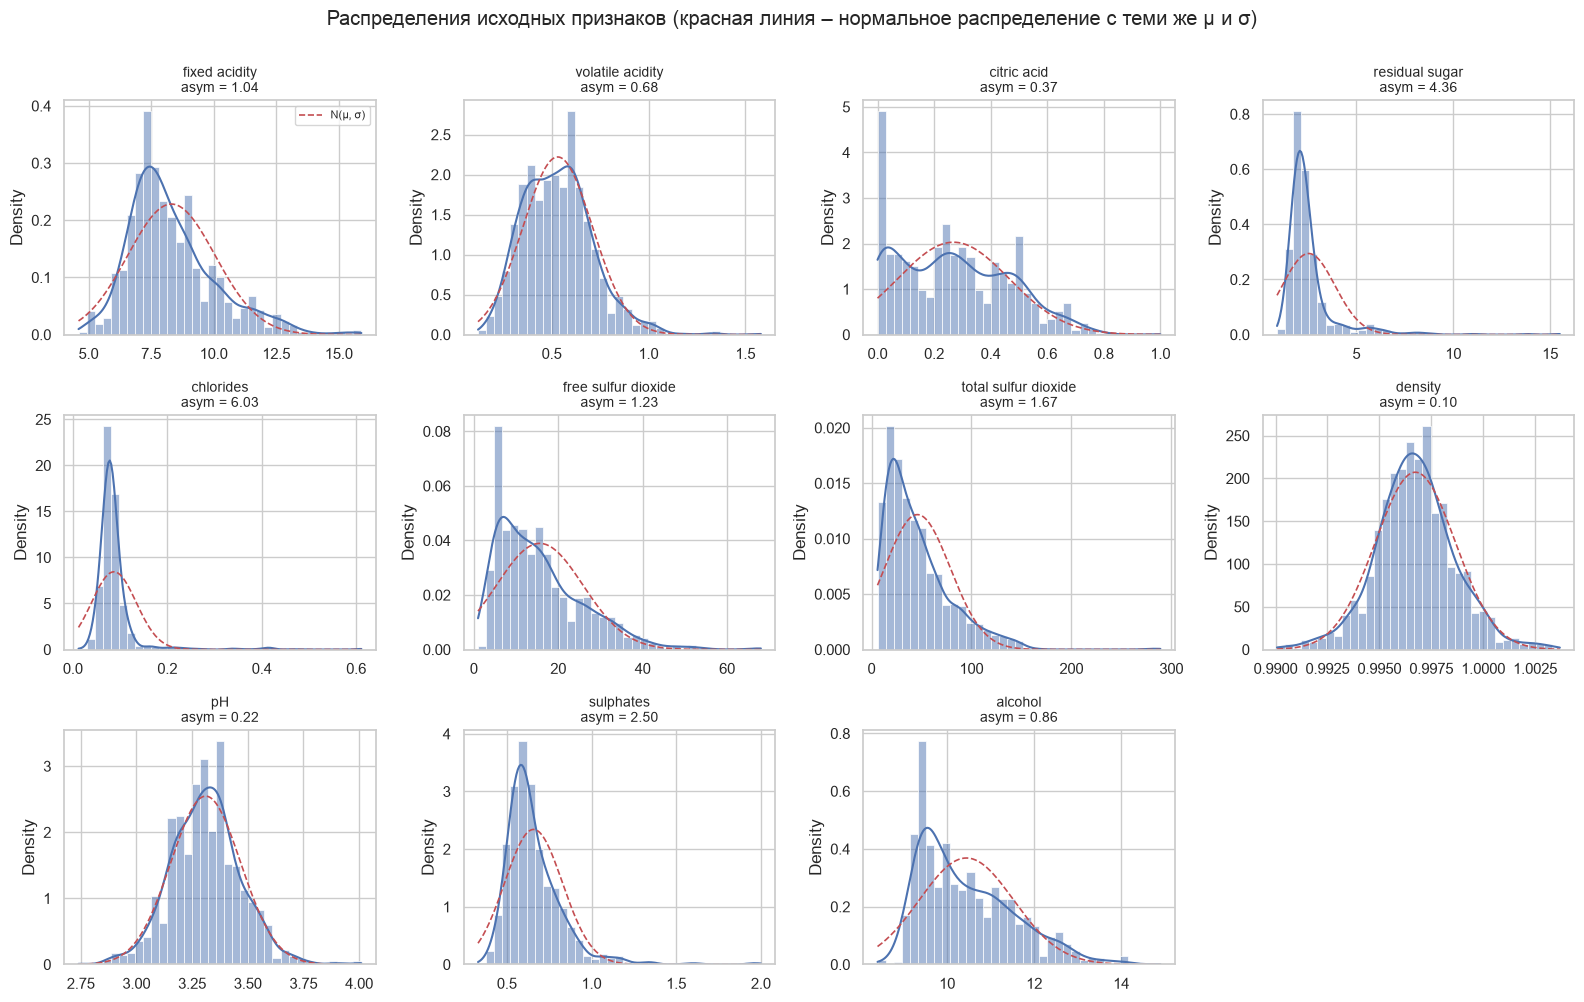

In [4]:
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col in zip(axes.flat, FEATURES):
    sns.histplot(X_raw[col], bins=35, kde=True, ax=ax, color="#4C72B0", stat="density")
    mu, sd = X_raw[col].mean(), X_raw[col].std()
    xs = np.linspace(X_raw[col].min(), X_raw[col].max(), 200)
    ax.plot(xs, stats.norm.pdf(xs, mu, sd), "r--", lw=1.2, label="N(μ, σ)")
    ax.set_title(f"{col}\nasym = {X_raw[col].skew():.2f}", fontsize=10)
    ax.set_xlabel("")
axes.flat[0].legend(fontsize=8)
axes.flat[-1].axis("off")
fig.suptitle("Распределения исходных признаков (красная линия – нормальное распределение с теми же μ и σ)", y=1.0)
plt.tight_layout()
plt.show()

Гистограммы подтверждают выводы по числовым характеристикам. Плотность и pH имеют унимодальные симметричные распределения, хорошо совпадающие с нормальной кривой. Остаточный сахар, хлориды и сульфаты сосредоточены в узком диапазоне, но имеют длинные правые хвосты из единичных образцов с аномально высокими значениями. Распределения диоксида серы и спирта скошены вправо. У лимонной кислоты заметен отдельный пик в нуле (вина без добавления лимонной кислоты).

Явной мультимодальности, которая указывала бы на хорошо разделённые группы по одному признаку, не видно. Это значит, что если кластеры существуют, то они проявляются лишь в совокупности нескольких признаков, а не по какому-то одному из них.

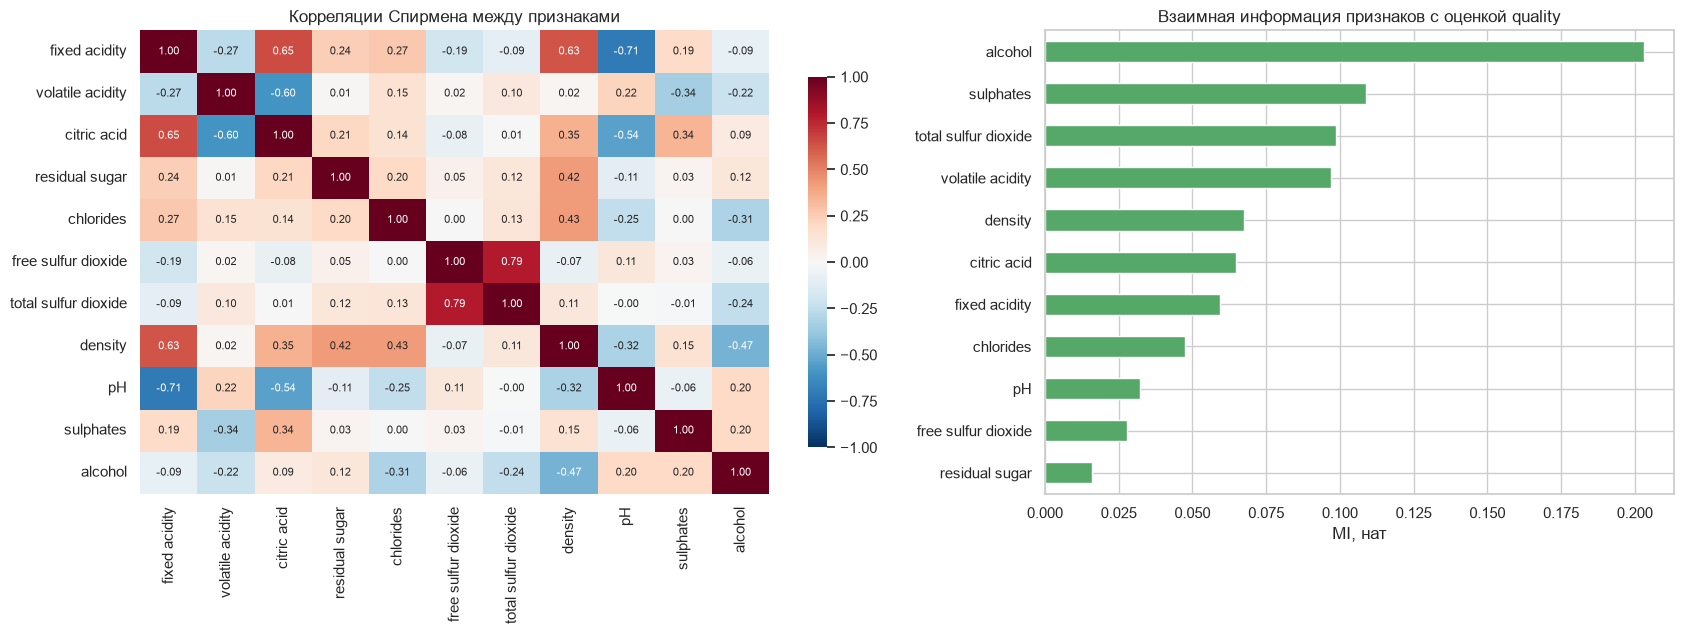

,"CV, %",max |r| с другими,MI с quality
alcohol,10.364,0.471,0.203
sulphates,25.908,0.344,0.109
total sulfur dioxide,71.398,0.794,0.099
volatile acidity,33.808,0.601,0.097
density,0.193,0.630,0.068
citric acid,73.291,0.654,0.065
fixed acidity,21.027,0.707,0.059
chlorides,54.372,0.427,0.048
pH,4.732,0.707,0.032
free sulfur dioxide,65.643,0.794,0.028


In [5]:
corr = X_raw.corr(method="spearman")
fig, axes = plt.subplots(1, 2, figsize=(17, 6.5), gridspec_kw={"width_ratios": [1.25, 1]})
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=axes[0],
            annot_kws={"size": 8}, cbar_kws={"shrink": 0.8})
axes[0].set_title("Корреляции Спирмена между признаками")

mi = pd.Series(mutual_info_classif(X_raw, quality, random_state=SEED), index=FEATURES)
signif = pd.DataFrame({
    "CV, %": desc["CV, %"],
    "max |r| с другими": corr.abs().where(~np.eye(len(FEATURES), dtype=bool)).max(),
    "MI с quality": mi,
}).sort_values("MI с quality", ascending=False)
signif["MI с quality"].plot.barh(ax=axes[1], color="#55A868")
axes[1].invert_yaxis()
axes[1].set_title("Взаимная информация признаков с оценкой quality")
axes[1].set_xlabel("MI, нат")
plt.tight_layout()
plt.show()
display(signif)

Информационная значимость признаков для кластеризации оценивалась с трёх сторон.

1. Вариативность. Коэффициент вариации у плотности (0.19 %) и pH (4.7 %) мал в абсолютном выражении, однако после стандартизации все признаки получают одинаковую дисперсию, поэтому малый CV сам по себе не делает признак бесполезным. Константных и почти константных признаков нет.
2. Избыточность. Сильнее всего связаны свободный и общий диоксид серы (ρ = 0.79), фиксированная кислотность с pH (ρ = −0.71) и с лимонной кислотой (0.65), а также с плотностью (0.63). Таким образом, в данных выделяется «кислотный» блок признаков (fixed acidity, citric acid, pH, density), который, как будет показано далее, и формирует главную ось кластерной структуры. Ни одна пара признаков не дублирует друг друга полностью (|ρ| < 0.8), поэтому все признаки сохранены.
3. Связь с качеством (справочно). Взаимная информация (MI) рассчитана с исходной шестиуровневой оценкой `quality` (баллы 3–8). Наибольшую MI имеют спирт (0.20 нат), сульфаты, общий диоксид серы и летучая кислотность (около 0.10), наименьшую – остаточный сахар (0.016) и свободный диоксид серы. Этот показатель приводится только для последующей интерпретации кластеров: кластеризация не использует оценку качества, поэтому отбирать признаки по MI было бы некорректно.

Итог: информационная значимость признаков для кластеризации оценивалась по их дисперсии (вариативности) и взаимным корреляциям. Все 11 признаков имеют ненулевой разброс, сильная мультиколлинеарность отсутствует, поэтому отбор признаков не проводился.

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
IQR (1.5),44,14,1,110,77,18,40,36,20,43,12
|z| > 3,9,5,1,23,21,13,10,12,5,21,7


Строк хотя бы с одним выбросом по IQR: 295 (25.8%)
Строк хотя бы с одним выбросом по |z| > 3: 97 (8.5%)


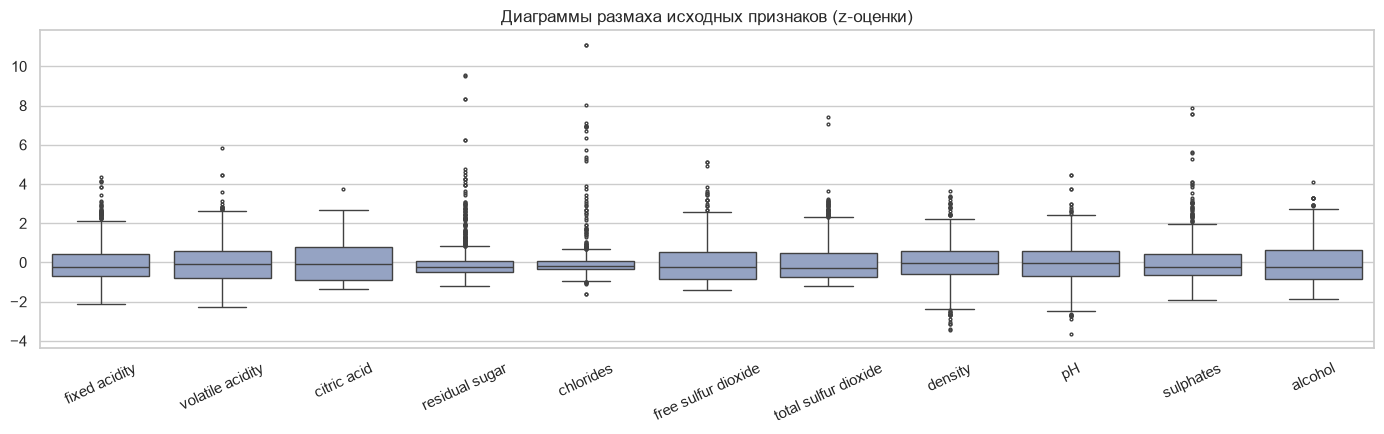

K-means на сырых данных, k = 4: размеры кластеров [19, 265, 333, 526]
K-means на сырых данных, k = 5: размеры кластеров [19, 232, 235, 251, 406]
K-means на сырых данных, k = 6: размеры кластеров [19, 133, 180, 183, 235, 393]


In [6]:
q1, q3 = X_raw.quantile(0.25), X_raw.quantile(0.75)
iqr = q3 - q1
iqr_mask = (X_raw < q1 - 1.5 * iqr) | (X_raw > q3 + 1.5 * iqr)
z_mask = pd.DataFrame(np.abs(stats.zscore(X_raw)) > 3, columns=FEATURES)
outl = pd.DataFrame({"IQR (1.5)": iqr_mask.sum(), "|z| > 3": z_mask.sum()})
display(outl.T)
print("Строк хотя бы с одним выбросом по IQR:", int(iqr_mask.any(axis=1).sum()),
      f"({iqr_mask.any(axis=1).mean():.1%})")
print("Строк хотя бы с одним выбросом по |z| > 3:", int(z_mask.any(axis=1).sum()),
      f"({z_mask.any(axis=1).mean():.1%})")

Xs_tmp = StandardScaler().fit_transform(X_raw)
fig, ax = plt.subplots(figsize=(14, 4.5))
sns.boxplot(data=pd.DataFrame(Xs_tmp, columns=FEATURES), ax=ax, color="#8DA0CB", fliersize=2)
ax.set_title("Диаграммы размаха исходных признаков (z-оценки)")
ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

# как выбросы влияют на K-means, если их не обрабатывать
for k in [4, 5, 6]:
    sizes = np.bincount(KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(Xs_tmp))
    print(f"K-means на сырых данных, k = {k}: размеры кластеров {sorted(sizes.tolist())}")

Анализ выбросов проводился двумя способами. По правилу 1.5·IQR хотя бы один выброс содержат 295 строк (25.8 %), причём больше всего их у остаточного сахара (110) и хлоридов (77). Такая большая доля не означает, что четверть данных «грязная». Она является следствием самого правила: строка считается выбросом, если хотя бы по одному из 11 признаков значение выходит за границы 1.5·IQR, а для асимметричных распределений с тяжёлым хвостом эти границы отсекают значительную часть вполне правдоподобных наблюдений. Даже при нормальном распределении признаков по 1.5·IQR помечается около 0.7 % значений каждого признака, и при 11 признаках доля строк хотя бы с одной пометкой заметно выше. Поэтому правило IQR использовалось здесь как ориентир, а для удаления был выбран более строгий критерий. По критерию |z| > 3 выбросы есть у 97 строк (8.5 %).

Диаграммы размаха показывают, что наиболее экстремальные значения (до 10–12 стандартных отклонений) приходятся на хлориды, сульфаты и остаточный сахар. Для методов, основанных на евклидовом расстоянии и средних (K-means, метод Уорда), такие точки опасны: они смещают центры и могут образовывать собственные микрокластеры. Проверка это подтверждает: K-means, применённый к стандартизованным сырым данным, при k = 4–6 выделяет отдельный микрокластер из 19 образцов – это вина с аномально высокими хлоридами и сульфатами. Следовательно, условие отсутствия выбросов на сырых данных не выполняется, и выбросы необходимо обработать на этапе предобработки.

## 3. Предобработка данных

Предобработка включает три шага: нормализацию формы распределений, удаление оставшихся выбросов и масштабирование.

1. К пяти признакам с сильной правосторонней асимметрией (residual sugar, chlorides, free sulfur dioxide, total sulfur dioxide, sulphates) применяется преобразование log(1 + x). Логарифм сжимает правый хвост, приближает распределение к симметричному и делает расстояния между «обычными» объектами и объектами из хвоста соизмеримыми. Функция log1p выбрана потому, что она определена и в нуле.
2. После логарифмирования удаляются объекты, у которых хотя бы по одному признаку |z| > 3. Удаление выполняется именно после преобразования: иначе по критерию трёх сигм удалялась бы значительная часть естественного хвоста асимметричных распределений.
3. Признаки стандартизуются (раздел 3.2).

Удалено наблюдений с |z| > 3 после логарифмирования: 86 (7.5%)
Размер очищенной выборки: (1057, 11)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
асимметрия: исходные,1.045,0.682,0.372,4.361,6.026,1.231,1.666,0.102,0.221,2.497,0.863
после log1p и очистки,0.885,0.392,0.345,1.502,1.819,-0.061,-0.010,0.090,0.126,0.826,0.755


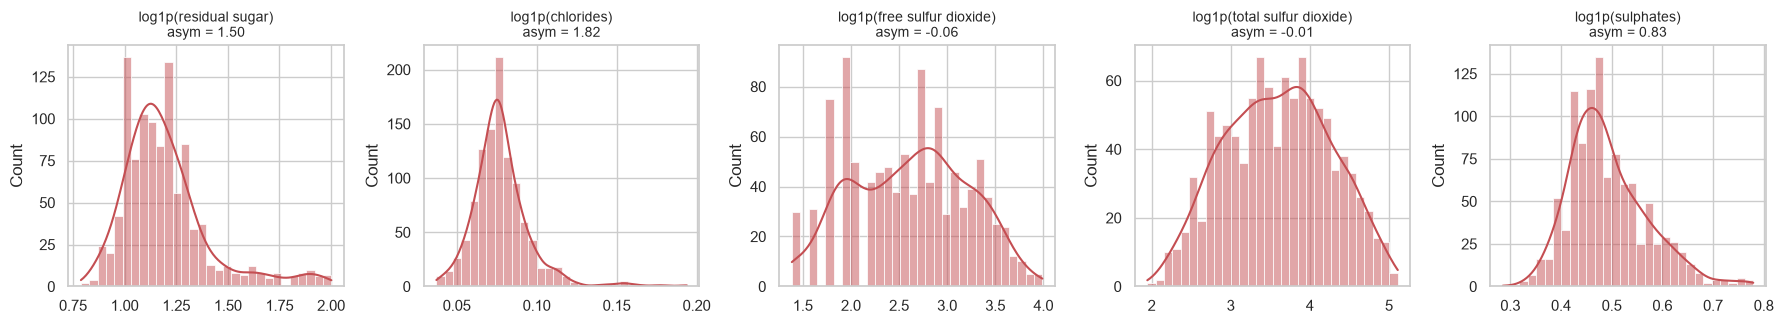

In [7]:
SKEWED = ["residual sugar", "chlorides", "free sulfur dioxide", "total sulfur dioxide", "sulphates"]
X_log = X_raw.copy()
X_log[SKEWED] = np.log1p(X_log[SKEWED])

z_log = np.abs(stats.zscore(X_log))
keep = (z_log <= 3).all(axis=1)
print("Удалено наблюдений с |z| > 3 после логарифмирования:", int((~keep).sum()),
      f"({(~keep).mean():.1%})")

X_clean_raw = X_raw[keep].reset_index(drop=True)     # исходные единицы – для интерпретации центров
X_clean = X_log[keep].reset_index(drop=True)         # пространство кластеризации
y_quality = quality[keep].reset_index(drop=True)
print("Размер очищенной выборки:", X_clean.shape)

skew_cmp = pd.DataFrame({
    "асимметрия: исходные": X_raw.skew(),
    "после log1p и очистки": X_clean.skew(),
})
display(skew_cmp.T)

fig, axes = plt.subplots(1, 5, figsize=(18, 3.4))
for ax, col in zip(axes, SKEWED):
    sns.histplot(X_clean[col], bins=30, kde=True, ax=ax, color="#C44E52")
    ax.set_title(f"log1p({col})\nasym = {X_clean[col].skew():.2f}", fontsize=10)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

После логарифмирования удалено 86 объектов (7.5 %), в очищенной выборке осталось 1 057 вин. Асимметрия диоксида серы практически исчезла (−0.06 и −0.01), у сульфатов снизилась с 2.50 до 0.83, у остаточного сахара – с 4.36 до 1.50, у хлоридов – с 6.03 до 1.82. Фиксированная кислотность (асимметрия 1.05) и спирт (0.86) не логарифмировались: их асимметрия меньше 1.2 и вызвана умеренно вытянутым хвостом, а не единичными экстремальными значениями. Их асимметрия также немного снизилась (до 0.89 и 0.76), но только за счёт удаления выбросов, а не за счёт преобразования. Остаточная асимметрия хлоридов и сахара связана с очень узким центральным пиком, который логарифмом не устраняется, однако экстремальных значений больше нет. Распределение оценок качества после очистки почти не изменилось (доля оценок ≥ 6 – 54 %), то есть удаление выбросов не исказило состав выборки.

Для интерпретации центров кластеров далее используется копия очищенных данных в исходных единицах измерения (`X_clean_raw`), а кластеризация выполняется на преобразованных признаках.

In [8]:
def hopkins(X, frac=0.1, seed=SEED):
    """Статистика Хопкинса H = Σu / (Σu + Σw): u – расстояния от равномерно
    распределённых точек до ближайшего объекта выборки, w – от объектов выборки
    до их ближайшего соседа. H ≈ 0.5 – случайные данные, H → 1 – выраженная кластерность."""
    rng = np.random.default_rng(seed)
    X = np.asarray(X)
    n, m = len(X), int(frac * len(X))
    nn = NearestNeighbors(n_neighbors=2).fit(X)
    w = nn.kneighbors(X[rng.choice(n, m, replace=False)], 2)[0][:, 1]
    U = rng.uniform(X.min(0), X.max(0), (m, X.shape[1]))
    u = nn.kneighbors(U, 1)[0][:, 0]
    return u.sum() / (u.sum() + w.sum())

Xh = StandardScaler().fit_transform(X_clean)
H = [hopkins(Xh, seed=s) for s in range(20)]
rng = np.random.default_rng(SEED)
H_unif = [hopkins(rng.uniform(Xh.min(0), Xh.max(0), Xh.shape), seed=s) for s in range(20)]
print(f"Хопкинс, данные:            {np.mean(H):.3f} ± {np.std(H):.3f}")
print(f"Хопкинс, равномерный шум:   {np.mean(H_unif):.3f} ± {np.std(H_unif):.3f}")

Хопкинс, данные:            0.792 ± 0.011
Хопкинс, равномерный шум:   0.500 ± 0.004


### 3.1. Проверка склонности данных к кластеризации

Осмысленность кластеризации проверялась статистикой Хопкинса H [8]. Она сравнивает расстояния от равномерно разбросанных точек до ближайшего объекта выборки (u) с расстояниями от объектов выборки до их ближайших соседей (w). Для данных без структуры H ≈ 0.5, для данных со сгущениями H стремится к 1.

Для стандартизованной выборки получено H = 0.792 ± 0.011 (20 повторений), тогда как для равномерного шума в том же объёме признакового пространства H = 0.500 ± 0.004. Значение заметно превышает 0.5, то есть объекты расположены неравномерно. Однако H = 0.792 следует трактовать как умеренную тенденцию к кластеризации, а не как выраженную кластерную структуру: для хорошо разделённых групп значение близко к 1. Иначе говоря, статистика подтверждает, что кластеризация осмысленна, но следует ожидать пересекающихся групп, а не изолированных «облаков».

### 3.2. Выбор метода масштабирования

Сравнивались три способа масштабирования: стандартизация (StandardScaler, z = (x − μ)/σ), нормализация в диапазон [0, 1] (MinMaxScaler) и робастное масштабирование по медиане и IQR (RobustScaler). Для каждого способа построено разбиение K-means при k = 2.

In [9]:
scalers = {"StandardScaler": StandardScaler(), "MinMaxScaler": MinMaxScaler(), "RobustScaler": RobustScaler()}
rows = []
for name, sc in scalers.items():
    Z = sc.fit_transform(X_clean)
    lab = KMeans(n_clusters=2, n_init=10, random_state=SEED).fit_predict(Z)
    spread = Z.std(axis=0)
    rows.append({
        "метод": name,
        "разброс σ признаков (min–max)": f"{spread.min():.2f}–{spread.max():.2f}",
        "силуэт (k=2)": silhouette_score(Z, lab),
        "CH (k=2)": calinski_harabasz_score(Z, lab),
        "размеры кластеров": sorted(np.bincount(lab).tolist()),
    })
display(pd.DataFrame(rows).set_index("метод"))

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_clean)
X_scaled_df = pd.DataFrame(X_scaled, columns=FEATURES)
display(X_scaled_df.describe().T[["mean", "std", "min", "max"]].round(3))

,разброс σ признаков (min–max),силуэт (k=2),CH (k=2),размеры кластеров
метод,,,,
StandardScaler,1.00–1.00,0.204,247.289,"[365, 692]"
MinMaxScaler,0.12–0.24,0.230,300.097,"[348, 709]"
RobustScaler,0.59–1.10,0.195,245.955,"[408, 649]"


,mean,std,min,max
fixed acidity,-0.0,1.0,-1.987,3.168
volatile acidity,-0.0,1.0,-2.387,3.127
citric acid,-0.0,1.0,-1.360,2.781
residual sugar,-0.0,1.0,-1.914,3.762
chlorides,0.0,1.0,-2.211,6.320
free sulfur dioxide,-0.0,1.0,-2.038,2.287
total sulfur dioxide,0.0,1.0,-2.489,2.275
density,-0.0,1.0,-3.141,3.155
pH,-0.0,1.0,-3.047,3.237
sulphates,0.0,1.0,-2.671,3.690


Выбрана стандартизация StandardScaler. Обоснование:

- только при стандартизации все признаки имеют одинаковую дисперсию (σ = 1) и, следовательно, одинаковый вклад в евклидово расстояние. При MinMax-нормализации стандартные отклонения признаков различаются вдвое (0.12–0.24): признак с одним крайним значением сжимается, и его вес в расстоянии искусственно уменьшается;
- MinMaxScaler даёт более высокий силуэт (0.230 против 0.204), но это артефакт. Силуэт вычисляется по расстояниям в том же пространстве, в котором построены кластеры, а в MinMax-пространстве признаки имеют другие веса, следовательно и другую геометрию: силуэт там измеряет разделимость по иному набору «весомых» признаков. Значения силуэта, полученные при разных масштабированиях, поэтому несопоставимы и не могут служить критерием выбора;
- RobustScaler нужен, когда в данных остаются выбросы. После логарифмирования и удаления |z| > 3 этого нет, а результат RobustScaler близок к стандартизации (силуэт 0.195, CH 246);
- стандартизация рекомендована для K-means и метода Уорда, поскольку оба метода минимизируют сумму квадратов отклонений и предполагают сопоставимые масштабы признаков.

После преобразования все признаки имеют нулевое среднее и единичное стандартное отклонение, значения лежат в диапазоне примерно от −3 до +3 (у хлоридов до 6.3 из-за узкого пика распределения).

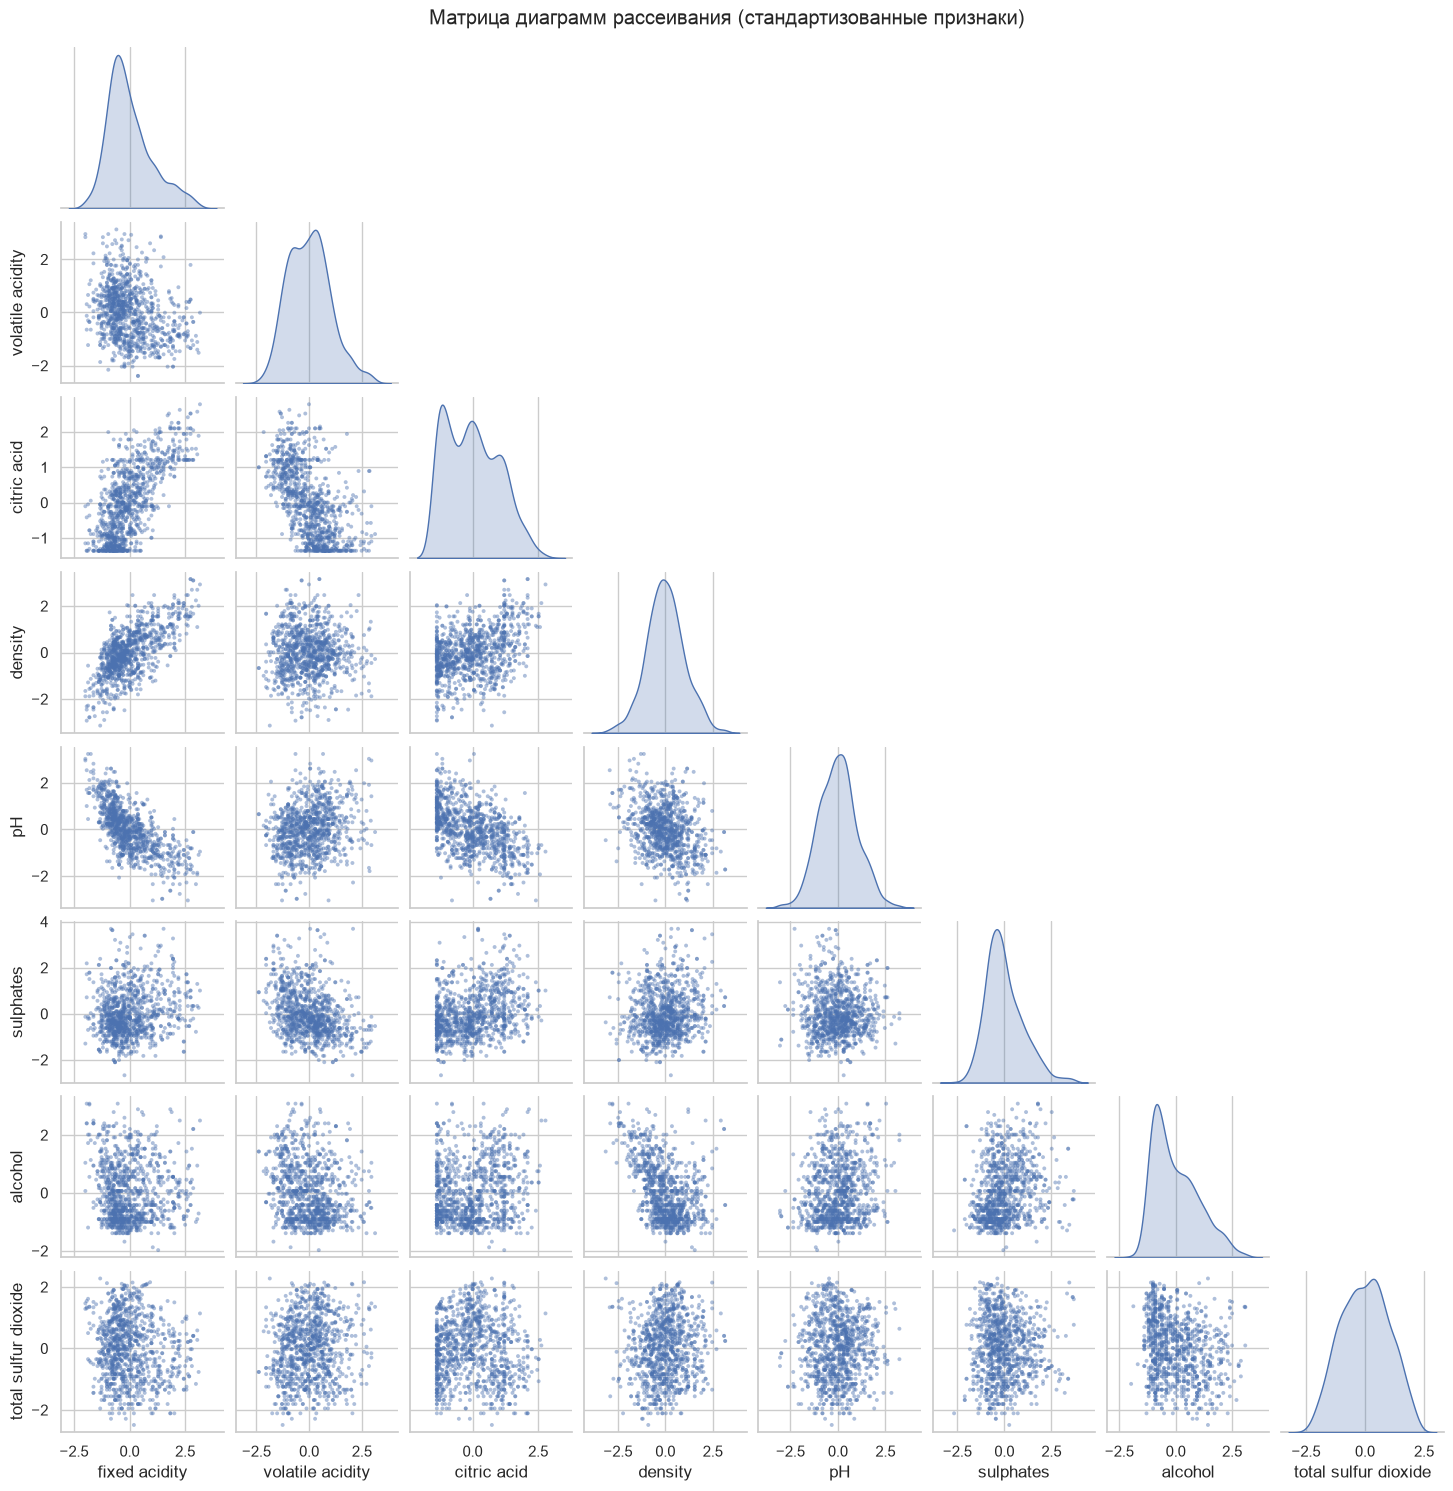

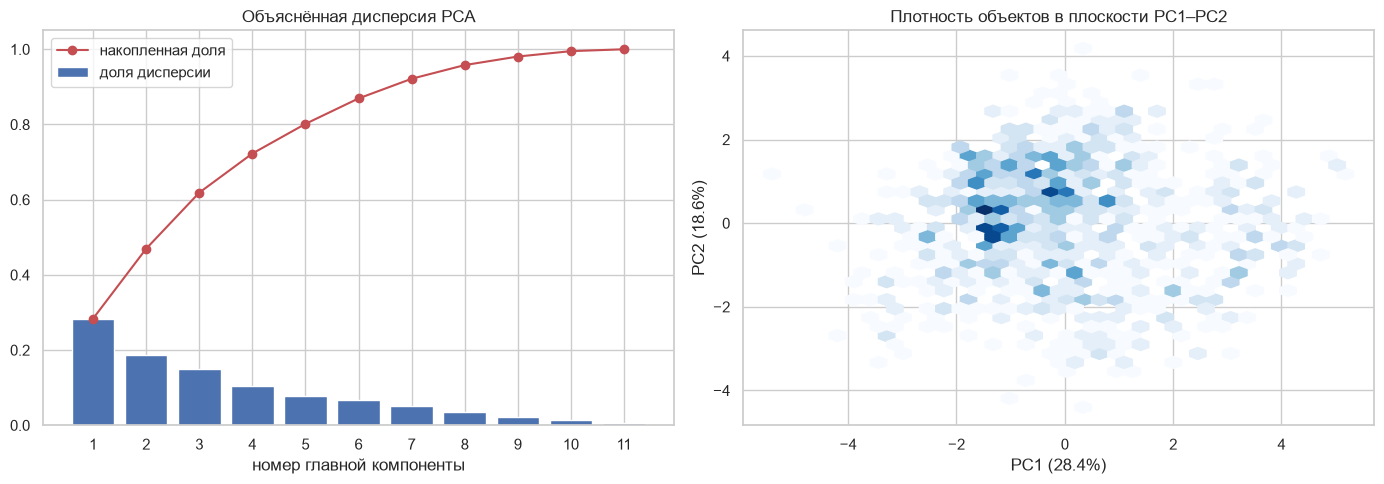

Накопленная доля дисперсии первых 2/3/5 компонент: [0.47  0.619 0.802]


,PC1,PC2,PC3
fixed acidity,0.516,0.036,-0.044
volatile acidity,-0.260,0.314,-0.353
citric acid,0.468,-0.130,0.223
residual sugar,0.190,0.099,0.039
chlorides,0.182,0.293,-0.189
free sulfur dioxide,-0.149,0.377,0.562
total sulfur dioxide,-0.075,0.493,0.481
density,0.390,0.348,-0.136
pH,-0.405,-0.065,0.077
sulphates,0.180,-0.190,0.377


In [10]:
PAIR = ["fixed acidity", "volatile acidity", "citric acid", "density", "pH", "sulphates", "alcohol",
        "total sulfur dioxide"]
g = sns.pairplot(X_scaled_df[PAIR], corner=True, diag_kind="kde",
                 plot_kws={"s": 8, "alpha": 0.45, "edgecolor": "none"}, height=1.85)
g.figure.suptitle("Матрица диаграмм рассеивания (стандартизованные признаки)", y=1.01)
plt.show()

pca_full = PCA(random_state=SEED).fit(X_scaled)
ev = pca_full.explained_variance_ratio_
X_pca = pca_full.transform(X_scaled)[:, :2]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(range(1, 12), ev, color="#4C72B0", label="доля дисперсии")
axes[0].plot(range(1, 12), np.cumsum(ev), "o-", color="#C44E52", label="накопленная доля")
axes[0].set_xlabel("номер главной компоненты"); axes[0].set_xticks(range(1, 12)); axes[0].legend()
axes[0].set_title("Объяснённая дисперсия PCA")
axes[1].hexbin(X_pca[:, 0], X_pca[:, 1], gridsize=35, cmap="Blues", mincnt=1)
axes[1].set_xlabel(f"PC1 ({ev[0]:.1%})"); axes[1].set_ylabel(f"PC2 ({ev[1]:.1%})")
axes[1].set_title("Плотность объектов в плоскости PC1–PC2")
plt.tight_layout()
plt.show()
print("Накопленная доля дисперсии первых 2/3/5 компонент:", np.cumsum(ev)[[1, 2, 4]].round(3))
loadings = pd.DataFrame(pca_full.components_[:3].T, index=FEATURES, columns=["PC1", "PC2", "PC3"])
display(loadings.round(3))

### 3.3. Визуальная оценка структуры данных

На матрицу диаграмм рассеивания вынесены 8 признаков, наиболее важных для структуры данных (кислотный блок, спирт, сульфаты, диоксид серы). Чётко отделённых друг от друга сгущений ни на одной из проекций не видно. В то же время облака точек вытянуты вдоль направления «fixed acidity – citric acid – density – (−pH)», а распределение лимонной кислоты двугорбое: группа вин с почти нулевым её содержанием и группа с содержанием около 0.4–0.5 г/дм³. Это указывает на то, что основное различие между объектами связано с кислотным профилем вина.

Проекция на первые две главные компоненты объясняет 47.0 % дисперсии (PC1 – 28.4 %, PC2 – 18.6 %), для 80 % дисперсии нужно 5 компонент. Доля 47 % невелика: более половины разброса данных в двумерной проекции не видна. Поэтому все визуальные выводы по PCA носят ориентировочный характер, а перекрытие групп на проекции может быть сильнее, чем в исходном 11-мерном пространстве, где кластеры частично разведены по остальным компонентам. Первая компонента – это как раз кислотная ось: наибольшие нагрузки у fixed acidity (0.52), citric acid (0.47), pH (−0.41) и density (0.39). Вторую компоненту формируют диоксид серы (0.49) и спирт (−0.49). На карте плотности видно одно основное сгущение, смещённое в сторону отрицательных значений PC1 (вина с низкой кислотностью), и более разреженный «шлейф» в сторону положительных PC1.

Выводы о структуре и выбор методов:

- ожидаемое число кластеров невелико – 2, возможно 3–5 при более детальном разбиении;
- кластеры не разделены зонами низкой плотности и, вероятно, касаются друг друга; после стандартизации облака имеют выпуклую, близкую к эллипсоидальной форму без «ленточных» или вложенных структур;
- плотность внутри данных меняется плавно, без чётких пустот, поэтому методы, основанные на плотности (DBSCAN), здесь малоэффективны: при любом ε они либо объединят почти все объекты в один кластер, либо отнесут большую часть данных к шуму.

Исходя из этого, выбраны два метода, ориентированные на компактные выпуклые кластеры:

1. K-means – минимизирует внутрикластерную сумму квадратов расстояний (WCSS), хорошо работает с выпуклыми кластерами сопоставимого размера, быстр и даёт интерпретируемые центры.
2. Агломеративная иерархическая кластеризация с методом связи Уорда – на каждом шаге объединяет пару кластеров с минимальным приростом WCSS. Она детерминирована, не требует начальной инициализации и строит дендрограмму, по которой можно независимо проверить выбор числа кластеров. Поскольку оба метода оптимизируют один и тот же критерий разными способами (итеративным и жадным), их сравнение позволяет оценить, насколько разбиение определяется самими данными, а не особенностями алгоритма.

## 4. Ход работы

### 4.1. Подбор оптимального числа кластеров

Для k от 2 до 10 строились разбиения K-means (`n_init=10`) и методом Уорда, для каждого вычислялись:

- WCSS (инерция) – сумма квадратов расстояний от объектов до центров своих кластеров; используется в методе локтя;
- средний коэффициент силуэта s ∈ [−1, 1] – показывает, насколько объект ближе к своему кластеру, чем к ближайшему чужому [3];
- индекс Calinski–Harabasz (CH) – отношение межкластерной дисперсии к внутрикластерной с поправкой на число кластеров (чем больше, тем лучше) [4];
- индекс Davies–Bouldin (DB) – среднее по кластерам отношение «разброс двух кластеров / расстояние между их центрами» (чем меньше, тем лучше) [5].

,WCSS (inertia),силуэт KM,CH KM,DB KM,силуэт Ward,CH Ward,DB Ward,Δ² WCSS
k,,,,,,,,
2,9419.171,0.204,247.289,1.909,0.198,219.319,1.966,NaN
3,8307.494,0.149,210.579,1.913,0.109,170.273,1.996,265.194
4,7461.009,0.159,195.987,1.763,0.112,152.028,1.994,291.636
5,6906.161,0.161,179.779,1.739,0.118,145.232,2.016,223.215
6,6574.527,0.135,161.537,1.795,0.097,135.433,1.991,40.311
7,6283.204,0.133,148.836,1.811,0.106,126.544,1.848,22.341
8,6014.221,0.141,139.854,1.758,0.102,119.639,1.869,28.098
9,5773.336,0.143,132.823,1.716,0.110,115.241,1.780,46.357
10,5578.807,0.136,126.121,1.717,0.116,110.131,1.711,NaN


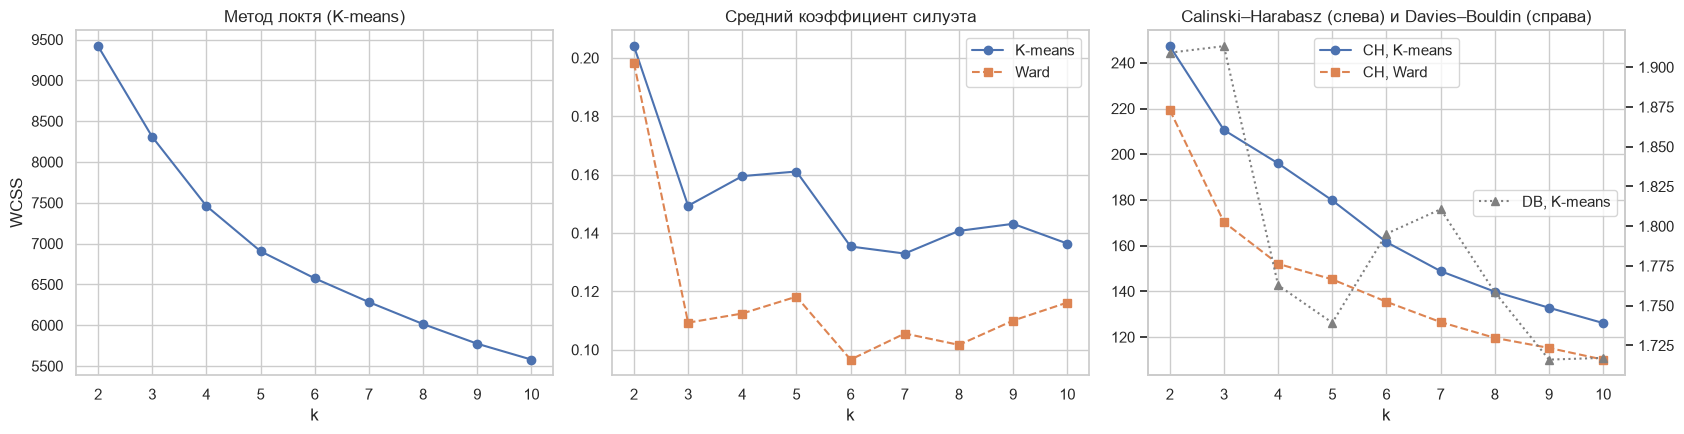

In [11]:
K_RANGE = range(2, 11)
rows = []
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X_scaled)
    ag = AgglomerativeClustering(n_clusters=k, linkage="ward").fit(X_scaled)
    rows.append({
        "k": k, "WCSS (inertia)": km.inertia_,
        "силуэт KM": silhouette_score(X_scaled, km.labels_),
        "CH KM": calinski_harabasz_score(X_scaled, km.labels_),
        "DB KM": davies_bouldin_score(X_scaled, km.labels_),
        "силуэт Ward": silhouette_score(X_scaled, ag.labels_),
        "CH Ward": calinski_harabasz_score(X_scaled, ag.labels_),
        "DB Ward": davies_bouldin_score(X_scaled, ag.labels_),
    })
k_tab = pd.DataFrame(rows).set_index("k")
# второй разностный критерий для «локтя»
k_tab["Δ² WCSS"] = k_tab["WCSS (inertia)"].diff().diff().shift(-1)
display(k_tab)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].plot(k_tab.index, k_tab["WCSS (inertia)"], "o-")
axes[0].set_title("Метод локтя (K-means)"); axes[0].set_xlabel("k"); axes[0].set_ylabel("WCSS")
axes[1].plot(k_tab.index, k_tab["силуэт KM"], "o-", label="K-means")
axes[1].plot(k_tab.index, k_tab["силуэт Ward"], "s--", label="Ward")
axes[1].set_title("Средний коэффициент силуэта"); axes[1].set_xlabel("k"); axes[1].legend()
axes[2].plot(k_tab.index, k_tab["CH KM"], "o-", label="CH, K-means")
axes[2].plot(k_tab.index, k_tab["CH Ward"], "s--", label="CH, Ward")
ax2 = axes[2].twinx()
ax2.plot(k_tab.index, k_tab["DB KM"], "^:", color="gray", label="DB, K-means")
axes[2].set_title("Calinski–Harabasz (слева) и Davies–Bouldin (справа)"); axes[2].set_xlabel("k")
axes[2].legend(loc="upper center"); ax2.legend(loc="center right"); ax2.grid(False)
plt.tight_layout()
plt.show()

Кривая WCSS убывает плавно и не имеет выраженного «локтя». Вторая разность, характеризующая изгиб кривой, максимальна при k = 4 (292) и k = 3 (265), а начиная с k = 6 падает до 20–45, то есть добавление кластеров после 5 почти не меняет характер убывания. Таким образом, метод локтя указывает лишь на диапазон k = 3–5 и сам по себе не позволяет уверенно выбрать k, что типично для данных с пересекающимися кластерами.

Силуэт для обоих методов максимален при k = 2 (0.204 у K-means, 0.198 у Уорда), при k = 3 резко падает (0.149 и 0.109), а для K-means имеет второй, более низкий локальный максимум при k = 5 (0.161). Индекс Calinski–Harabasz также максимален при k = 2 и монотонно убывает. Индекс Davies–Bouldin меняется слабо (1.72–1.91) и немного улучшается при больших k, поскольку мелкие кластеры компактнее; явного минимума он не даёт.

Абсолютные значения силуэта (около 0.2) невелики: по шкале Кауфмана и Руссеу [3] значения 0.26–0.50 соответствуют «слабой» структуре, а ниже 0.25 – структуре, которая может быть артефактом. Это согласуется со статистикой Хопкинса: группы в данных есть, но они не изолированы.

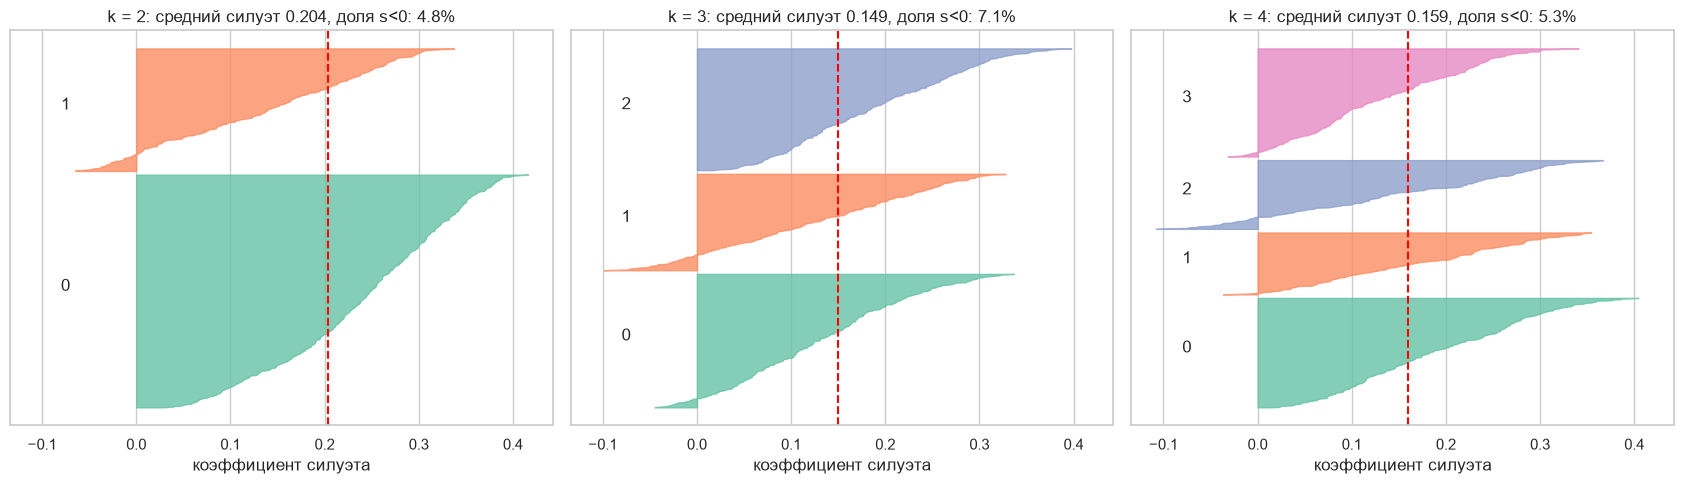

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharex=True)
for ax, k in zip(axes, [2, 3, 4]):
    lab = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(X_scaled)
    s = silhouette_samples(X_scaled, lab)
    y0 = 10
    for c in range(k):
        sc = np.sort(s[lab == c])
        ax.fill_betweenx(np.arange(y0, y0 + len(sc)), 0, sc, alpha=0.8, color=sns.color_palette("Set2")[c])
        ax.text(-0.08, y0 + len(sc) / 2, str(c))
        y0 += len(sc) + 10
    ax.axvline(s.mean(), color="red", ls="--")
    ax.set_title(f"k = {k}: средний силуэт {s.mean():.3f}, доля s<0: {(s < 0).mean():.1%}")
    ax.set_yticks([]); ax.set_xlabel("коэффициент силуэта")
plt.tight_layout()
plt.show()

Силуэтные профили позволяют оценить качество разбиения на уровне отдельных объектов. При k = 2 оба кластера имеют сопоставимые профили, превышающие средний уровень у значительной части объектов, а доля объектов с отрицательным силуэтом (то есть «попавших не в свой кластер») минимальна – 4.8 %. При k = 3 доля отрицательных значений возрастает до 7.1 %, а кластер 1 имеет заметно более низкие силуэты, чем остальные: он лежит между двумя другими группами. При k = 4 профили выравниваются, но средний силуэт всё равно ниже, чем при k = 2.

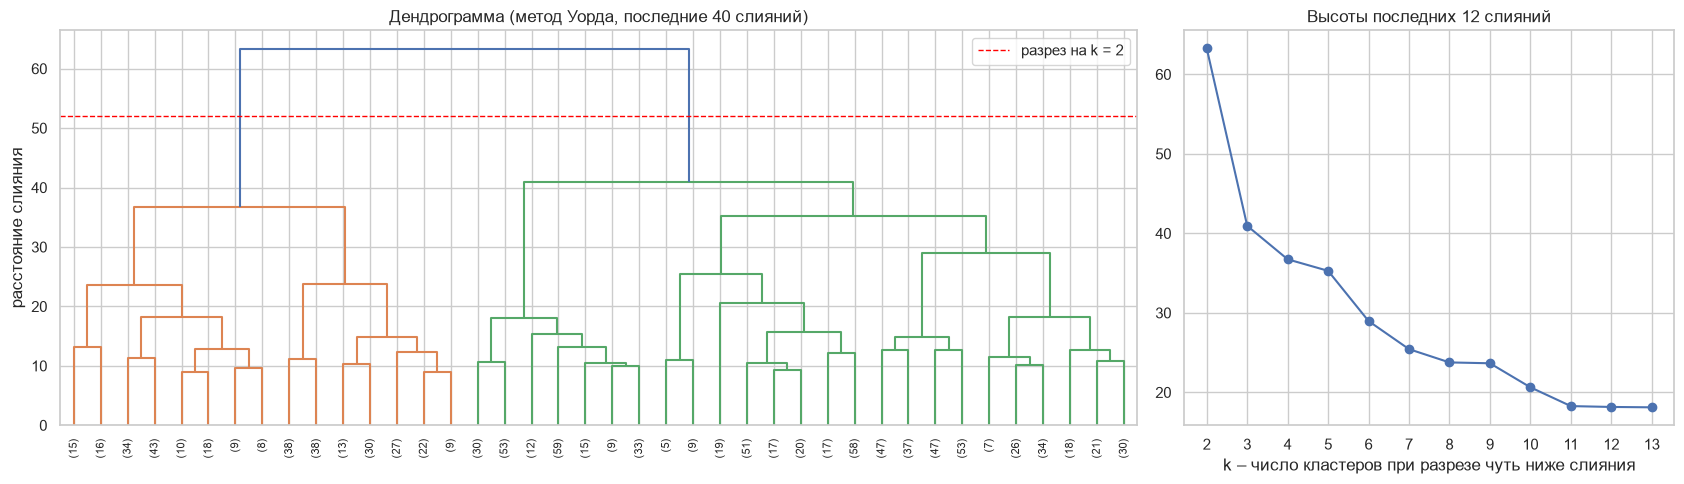

Ширина интервала высот, в котором разрез даёт k кластеров:
k = 2    22.32
k = 3     4.21
k = 4     1.45
k = 5     6.32
k = 6     3.53
k = 7     1.67


In [13]:
Z_ward = linkage(X_scaled, method="ward")
cut2 = (Z_ward[-1, 2] + Z_ward[-2, 2]) / 2        # уровень разреза, дающий два кластера
fig, axes = plt.subplots(1, 2, figsize=(17, 5), gridspec_kw={"width_ratios": [2.2, 1]})
dendrogram(Z_ward, truncate_mode="lastp", p=40, show_leaf_counts=True, leaf_rotation=90,
           leaf_font_size=8, ax=axes[0], color_threshold=cut2)
axes[0].axhline(cut2, color="red", ls="--", lw=1, label="разрез на k = 2")
axes[0].legend()
axes[0].set_title("Дендрограмма (метод Уорда, последние 40 слияний)")
axes[0].set_ylabel("расстояние слияния")
last = Z_ward[-12:, 2][::-1]
axes[1].plot(range(2, 14), last, "o-")
axes[1].set_xticks(range(2, 14))
axes[1].set_title("Высоты последних 12 слияний")
axes[1].set_xlabel("k – число кластеров при разрезе чуть ниже слияния")
plt.tight_layout()
plt.show()
gaps = pd.Series(-np.diff(last), index=[f"k = {k}" for k in range(2, 13)])
print("Ширина интервала высот, в котором разрез даёт k кластеров:")
print(gaps.round(2).head(6).to_string())

Дендрограмма метода Уорда даёт независимую оценку числа кластеров. Последнее слияние происходит на высоте ≈ 63, предыдущее – на высоте ≈ 41. Ширина интервала высот, на котором разрез дендрограммы даёт два кластера, равна 22.3, что в 3.5 раза больше любого другого интервала (следующие по величине – 6.3 для k = 5 и 4.2 для k = 3). Это означает, что разбиение на два кластера является наиболее устойчивым к выбору уровня разреза.

**Итоговый выбор: k = 2.** В его пользу говорят силуэт, индекс Calinski–Harabasz и дендрограмма; метод локтя этому не противоречит. Разбиение на k = 3 рассматривается дополнительно в разделах 4.4 и 5 как более детальный вариант.

### 4.2. Реализация двух методов кластеризации

Параметры моделей:

- K-means: `n_clusters=2`, `init="k-means++"`, `n_init=10` (лучший из 10 запусков с разными начальными центрами по критерию WCSS), `random_state=42`;
- агломеративная кластеризация: `n_clusters=2`, `linkage="ward"`, евклидова метрика (метод Уорда определён только для неё).

Номера кластеров приведены к единому виду: кластер 1 – группа с более высокой фиксированной кислотностью.

In [14]:
K_OPT = 2
kmeans = KMeans(n_clusters=K_OPT, n_init=10, random_state=SEED).fit(X_scaled)
labels_km = kmeans.labels_
ward = AgglomerativeClustering(n_clusters=K_OPT, linkage="ward").fit(X_scaled)
labels_hc = ward.labels_

# согласуем номера: кластер 1 – группа с более высокой фиксированной кислотностью
def align(lab):
    m = pd.Series(X_clean["fixed acidity"]).groupby(lab).mean()
    return lab if m[1] > m[0] else 1 - lab
labels_km, labels_hc = align(labels_km), align(labels_hc)

print("Размеры кластеров K-means:", np.bincount(labels_km))
print("Размеры кластеров Ward:   ", np.bincount(labels_hc))
print("Число итераций K-means:", kmeans.n_iter_, " | инерция:", round(kmeans.inertia_, 1))
cross = pd.crosstab(pd.Series(labels_km, name="K-means"), pd.Series(labels_hc, name="Ward"))
display(cross)
print(f"Совпадение меток двух методов: {(labels_km == labels_hc).mean():.1%}, "
      f"ARI между методами: {adjusted_rand_score(labels_km, labels_hc):.3f}")

Размеры кластеров K-means: [692 365]
Размеры кластеров Ward:    [727 330]
Число итераций K-means: 10  | инерция: 9419.2


Ward,0,1
K-means,,
0,663,29
1,64,301


Совпадение меток двух методов: 91.2%, ARI между методами: 0.674


K-means сошёлся за 10 итераций и выделил кластеры из 692 и 365 вин, метод Уорда – из 727 и 330. Методы совпадают на 91.2 % объектов (ARI между разбиениями 0.674). Основное расхождение – 64 объекта, которые K-means относит к кластеру 1, а метод Уорда к кластеру 0. Эти объекты находятся на границе между группами, где жадная процедура слияния Уорда, зафиксировав решение на ранних шагах, уже не может его исправить, тогда как K-means перераспределяет объекты на каждой итерации.

### 4.3. Метрики качества

Внутренние метрики (силуэт, CH, DB) оценивают геометрию разбиения без привлечения внешней информации. Внешние метрики сравнивают кластеры с известной разметкой. В качестве разметки взят бинарный признак «quality ≥ 6» («хорошее» вино), соответствующий двум кластерам. В очищенной выборке он делит объекты в соотношении 54 / 46 (571 «хорошее» вино против 486 «обычных»), то есть классы близки по размеру, но не равны. Использовались:

- индекс Rand – доля пар объектов, которые одинаково (вместе или раздельно) отнесены и кластеризацией, и разметкой;
- скорректированный индекс Rand (ARI) [6] – индекс Rand с поправкой на случайное совпадение: 0 для случайного разбиения, 1 для полного совпадения;
- индекс Жаккара для пар – TP / (TP + FP + FN), где TP – пары, находящиеся вместе в обоих разбиениях;
- индекс Фоулкса – Мэллоуса – среднее геометрическое точности и полноты по парам;
- NMI, однородность (homogeneity) и полнота (completeness) – метрики на основе взаимной информации;
- чистота (purity) – доля объектов, принадлежащих преобладающему в своём кластере классу.

Для правильного прочтения абсолютных значений в таблицу добавлен столбец «случайные метки» – метрики для случайной перестановки меток K-means (среднее по 20 перестановкам).

In [15]:
def jaccard_pairs(a, b):
    (tn, fp), (fn, tp) = pair_confusion_matrix(a, b)
    return tp / (tp + fp + fn)

def purity(y, lab):
    cm = contingency_matrix(y, lab)
    return cm.max(axis=0).sum() / cm.sum()

y_bin = (y_quality >= 6).astype(int).values   # «хорошее» (≥ 6) / «обычное» (≤ 5)

def all_metrics(lab):
    h, c, v = homogeneity_completeness_v_measure(y_bin, lab)
    return {
        "Силуэт ↑": silhouette_score(X_scaled, lab),
        "Calinski–Harabasz ↑": calinski_harabasz_score(X_scaled, lab),
        "Davies–Bouldin ↓": davies_bouldin_score(X_scaled, lab),
        "Rand index ↑": rand_score(y_bin, lab),
        "Adjusted Rand ↑": adjusted_rand_score(y_bin, lab),
        "Jaccard (пары) ↑": jaccard_pairs(y_bin, lab),
        "Fowlkes–Mallows ↑": fowlkes_mallows_score(y_bin, lab),
        "NMI ↑": normalized_mutual_info_score(y_bin, lab),
        "Homogeneity ↑": h, "Completeness ↑": c,
        "Purity ↑": purity(y_bin, lab),
    }

metrics = pd.DataFrame({"K-means (k=2)": all_metrics(labels_km), "Ward (k=2)": all_metrics(labels_hc)})
# опорные значения: случайное разбиение тех же размеров
rng = np.random.default_rng(SEED)
metrics["случайные метки"] = pd.DataFrame(
    [all_metrics(rng.permutation(labels_km)) for _ in range(20)]).mean()
display(metrics.round(3))

for name, lab in [("K-means", labels_km), ("Ward", labels_hc)]:
    ct = pd.crosstab(pd.Series(lab, name=f"кластер {name}"), y_quality.rename("quality"))
    ct["доля quality ≥ 6"] = (ct[[6, 7, 8]].sum(axis=1) / ct.sum(axis=1)).round(3)
    display(ct)

,K-means (k=2),Ward (k=2),случайные метки
Силуэт ↑,0.204,0.198,-0.000
Calinski–Harabasz ↑,247.289,219.319,0.910
Davies–Bouldin ↓,1.909,1.966,34.402
Rand index ↑,0.521,0.534,0.500
Adjusted Rand ↑,0.042,0.068,-0.000
Jaccard (пары) ↑,0.374,0.395,0.355
Fowlkes–Mallows ↑,0.545,0.567,0.525
NMI ↑,0.047,0.081,0.001
Homogeneity ↑,0.045,0.077,0.001
Completeness ↑,0.048,0.086,0.001


quality,3,4,5,6,7,8,доля quality ≥ 6
кластер K-means,,,,,,,
0,3,26,351,273,36,3,0.451
1,2,4,100,153,94,12,0.710


quality,3,4,5,6,7,8,доля quality ≥ 6
кластер Ward,,,,,,,
0,4,25,383,276,36,3,0.433
1,1,5,68,150,94,12,0.776


Интерпретация внутренних метрик. Оба метода существенно лучше случайного разбиения: силуэт 0.20 против 0, CH ≈ 220–250 против ≈ 1, DB ≈ 1.9 против 34. K-means немного превосходит метод Уорда по всем трём внутренним метрикам (силуэт 0.204 против 0.198, CH 247 против 219, DB 1.91 против 1.97). Это закономерно: K-means напрямую оптимизирует внутрикластерную сумму квадратов, а метод Уорда минимизирует её только локально на каждом шаге слияния. Значение DB > 1 означает, что средний разброс кластеров больше расстояния между их центрами, то есть кластеры пересекаются.

Интерпретация внешних метрик. Индекс Rand (0.52–0.53) и индекс Жаккара (0.37–0.40) лишь незначительно превышают значения для случайных меток (0.50 и 0.36). Это показывает, почему нескорректированные индексы нужно сравнивать с базовым уровнем: при двух классах примерно равного размера даже случайное разбиение даёт Rand ≈ 0.5. Скорректированные метрики ARI (0.042 и 0.068) и NMI (0.047 и 0.081) положительны, но малы. Метод Уорда согласуется с качеством немного лучше K-means.

Вывод: кластеры не совпадают с делением на «хорошие» и «обычные» вина. Это не недостаток кластеризации, а содержательный результат: алгоритмы группируют вина по химическому составу, а экспертная оценка зависит от состава лишь частично. Тем не менее связь есть и она устойчива: в кластере 1 доля вин с оценкой ≥ 6 составляет 71 % (у Уорда – 78 %), а в кластере 0 – 45 % (43 %). Средняя оценка в кластере 1 выше на 0.55–0.67 балла, а почти все вина с оценкой 8 (12 из 15) попали в кластер 1.

In [16]:
def cluster_geometry(X, lab):
    ks = np.unique(lab)
    centers = np.vstack([X[lab == c].mean(0) for c in ks])
    rows = []
    for c in ks:
        P = X[lab == c]
        d_c = np.linalg.norm(P - centers[c], axis=1)
        rows.append({
            "кластер": c, "n": len(P),
            "ср. расст. до центра": d_c.mean(),
            "RMS-радиус": np.sqrt((d_c ** 2).mean()),
            "ср. попарное расст.": pdist(P).mean(),
            "диаметр": pdist(P).max(),
            "WCSS": (d_c ** 2).sum(),
        })
    geo = pd.DataFrame(rows).set_index("кластер")
    D = cdist(X[lab == 0], X[lab == 1])
    between = {
        "между центрами": np.linalg.norm(centers[0] - centers[1]),
        "ближайшие точки (single)": D.min(),
        "среднее (average)": D.mean(),
        "дальние точки (complete)": D.max(),
    }
    return geo, pd.Series(between), centers

for name, lab in [("K-means", labels_km), ("Ward", labels_hc)]:
    geo, between, centers = cluster_geometry(X_scaled, lab)
    print(f"=== {name} ===")
    display(geo.round(3))
    print("Межкластерные расстояния:", between.round(3).to_dict())
    print("Отношение межцентрового расстояния к среднему радиусу:",
          round(between["между центрами"] / geo["ср. расст. до центра"].mean(), 3))

=== K-means ===


,n,ср. расст. до центра,RMS-радиус,ср. попарное расст.,диаметр,WCSS
кластер,,,,,,
0,692,2.710,2.857,3.858,9.884,5647.346
1,365,3.093,3.215,4.364,10.156,3771.826


Межкластерные расстояния: {'между центрами': 3.04, 'ближайшие точки (single)': 0.707, 'среднее (average)': 5.1, 'дальние точки (complete)': 12.051}
Отношение межцентрового расстояния к среднему радиусу: 1.048
=== Ward ===


,n,ср. расст. до центра,RMS-радиус,ср. попарное расст.,диаметр,WCSS
кластер,,,,,,
0,727,2.774,2.946,3.956,12.051,6308.236
1,330,3.065,3.171,4.308,10.287,3317.679


Межкластерные расстояния: {'между центрами': 2.969, 'ближайшие точки (single)': 1.185, 'среднее (average)': 5.096, 'дальние точки (complete)': 11.416}
Отношение межцентрового расстояния к среднему радиусу: 1.017


Для каждого кластера вычислены среднее расстояние объектов до центра, среднеквадратичный радиус, среднее попарное расстояние, диаметр и вклад в WCSS, а также четыре варианта расстояния между кластерами: между центрами, между ближайшими точками (single link), среднее (average link) и между самыми удалёнными точками (complete link).

Для K-means кластер 0 (692 вина) более компактен: среднее расстояние до центра 2.71 против 3.09 у кластера 1, среднее попарное расстояние 3.86 против 4.36. Иначе говоря, вина первой группы однороднее, а вторая группа более разнородна, хотя и меньше по размеру. Расстояние между центрами (3.04) лишь на 5 % превышает средний радиус кластера, а минимальное расстояние между точками разных кластеров равно всего 0.71 при среднем попарном расстоянии внутри кластеров около 4. Следовательно, кластеры примыкают друг к другу, и граница между ними проходит через область достаточно высокой плотности. Это количественно подтверждает вывод о пересекающейся структуре, сделанный по силуэту и индексу DB.

Метод Уорда даёт похожую геометрию: радиусы 2.77 и 3.07, расстояние между центрами 2.97. Его кластер 0 крупнее и имеет больший диаметр (12.05), поскольку включает часть пограничных объектов. Суммарная WCSS у Уорда выше (9 626 против 9 419), то есть по критерию компактности решение K-means лучше.

Центры кластеров в стандартизованном пространстве (средние z-оценки):


,KM 0,KM 1,Ward 0,Ward 1
fixed acidity,-0.50,0.94,-0.41,0.90
volatile acidity,0.41,-0.78,0.40,-0.88
citric acid,-0.55,1.05,-0.49,1.08
residual sugar,-0.13,0.24,-0.06,0.14
chlorides,-0.06,0.11,0.01,-0.02
free sulfur dioxide,0.17,-0.33,0.15,-0.32
total sulfur dioxide,0.18,-0.35,0.18,-0.40
density,-0.22,0.43,-0.12,0.26
pH,0.35,-0.66,0.28,-0.62
sulphates,-0.30,0.56,-0.29,0.63


Медианы признаков по кластерам в исходных единицах:


,KM 0,KM 1,Ward 0,Ward 1,вся выборка
fixed acidity,7.400,9.800,7.500,9.600,7.900
volatile acidity,0.600,0.380,0.590,0.370,0.530
citric acid,0.130,0.460,0.140,0.465,0.240
residual sugar,2.100,2.300,2.100,2.300,2.200
chlorides,0.078,0.080,0.079,0.078,0.079
free sulfur dioxide,15.000,9.000,15.000,9.000,13.000
total sulfur dioxide,42.000,27.000,42.000,26.000,36.000
density,0.996,0.997,0.996,0.997,0.997
pH,3.360,3.220,3.360,3.220,3.310
sulphates,0.590,0.700,0.590,0.720,0.610


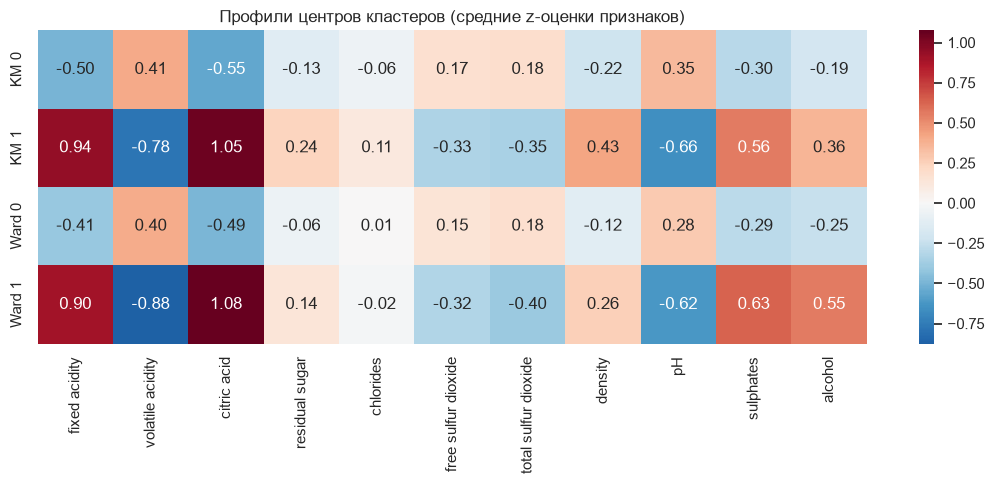

In [17]:
cent_scaled = pd.DataFrame(
    {f"KM {c}": X_scaled[labels_km == c].mean(0) for c in [0, 1]} |
    {f"Ward {c}": X_scaled[labels_hc == c].mean(0) for c in [0, 1]}, index=FEATURES)

cent_raw = pd.DataFrame(
    {f"KM {c}": X_clean_raw[labels_km == c].median() for c in [0, 1]} |
    {f"Ward {c}": X_clean_raw[labels_hc == c].median() for c in [0, 1]} |
    {"вся выборка": X_clean_raw.median()})
cent_raw.loc["quality (среднее)"] = [y_quality[labels_km == 0].mean(), y_quality[labels_km == 1].mean(),
                                     y_quality[labels_hc == 0].mean(), y_quality[labels_hc == 1].mean(),
                                     y_quality.mean()]
print("Центры кластеров в стандартизованном пространстве (средние z-оценки):")
display(cent_scaled.round(2))
print("Медианы признаков по кластерам в исходных единицах:")
display(cent_raw.round(3))

fig, ax = plt.subplots(figsize=(11, 5))
sns.heatmap(cent_scaled.T, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax)
ax.set_title("Профили центров кластеров (средние z-оценки признаков)")
plt.tight_layout()
plt.show()

Центры кластеров (в z-оценках и в медианах исходных величин) у двух методов практически совпадают, что говорит об устойчивости выделенных групп.

Кластер 0 («мягкие» вина с низкой кислотностью, 692 образца у K-means). Фиксированная кислотность ниже средней (медиана 7.4 против 7.9 г/дм³ по выборке), лимонной кислоты почти нет (0.13 г/дм³), pH выше (3.36), летучая кислотность повышена (0.60 г/дм³), содержание диоксида серы выше (общий – 42 мг/дм³), спирт и сульфаты ниже среднего (9.9 % и 0.59 г/дм³). Средняя оценка качества 5.47.

Кластер 1 («структурные» вина с высокой кислотностью, 365 образцов). Высокая фиксированная кислотность (9.8 г/дм³) и содержание лимонной кислоты (0.46 г/дм³), низкий pH (3.22), низкая летучая кислотность (0.38 г/дм³), меньше диоксида серы (общий – 27 мг/дм³), больше сульфатов (0.70 г/дм³) и спирта (10.8 %), чуть выше плотность. Средняя оценка 6.01 (у Уорда 6.11).

Хлориды и остаточный сахар у двух кластеров почти одинаковы (|z| ≤ 0.24), то есть в разделении групп они не участвуют. Главные различия – кислотный профиль (fixed acidity, citric acid, pH; |z| от 0.35 до 1.05) и противоположно направленная летучая кислотность. С точки зрения энологии это соответствует известным закономерностям: высокая летучая кислотность (уксусный тон) снижает оценку, а лимонная кислота, сульфаты и спирт её повышают. Именно поэтому кластер с «правильным» кислотным балансом в среднем оценивается выше, хотя кластеризация не использовала оценку качества.

### 4.4. Влияние параметров на качество кластеризации

Исследовалось влияние четырёх факторов:

1. числа кластеров k у K-means – на внутренние метрики и на согласие с трёхуровневой разметкой качества (≤ 5 / 6 / ≥ 7);
2. способа инициализации (`k-means++` и `random`) и числа перезапусков `n_init` – на достигаемую WCSS и воспроизводимость решения (30 запусков с разными `random_state`);
3. объёма выборки – устойчивость решений обоих методов при случайном отборе 80 % объектов (30 повторений, ARI с решением на полной выборке);
4. метода связи в иерархической кластеризации (`ward`, `complete`, `average`, `single`).

In [18]:
# 1) влияние k: внутренние и внешние метрики (внешняя – по трём уровням качества)
y3 = pd.cut(y_quality, [0, 5, 6, 10], labels=[0, 1, 2]).astype(int).values   # ≤5 / 6 / ≥7
rows = []
for k in range(2, 11):
    lab = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(X_scaled)
    sizes = np.bincount(lab)
    rows.append({"k": k, "силуэт": silhouette_score(X_scaled, lab),
                 "CH": calinski_harabasz_score(X_scaled, lab), "DB": davies_bouldin_score(X_scaled, lab),
                 "ARI (3 уровня)": adjusted_rand_score(y3, lab),
                 "NMI (3 уровня)": normalized_mutual_info_score(y3, lab),
                 "мин. кластер": sizes.min(), "макс. кластер": sizes.max()})
param_k = pd.DataFrame(rows).set_index("k")
display(param_k.round(3))

,силуэт,CH,DB,ARI (3 уровня),NMI (3 уровня),мин. кластер,макс. кластер
k,,,,,,,
2,0.204,247.289,1.909,0.090,0.074,365,692
3,0.149,210.579,1.913,0.057,0.068,290,401
4,0.159,195.987,1.763,0.097,0.119,188,332
5,0.161,179.779,1.739,0.101,0.122,139,314
6,0.135,161.537,1.795,0.067,0.106,122,240
7,0.133,148.836,1.811,0.065,0.097,88,231
8,0.141,139.854,1.758,0.066,0.104,45,220
9,0.143,132.823,1.716,0.064,0.102,29,233
10,0.136,126.121,1.717,0.052,0.104,28,194


С ростом k внутренние метрики в целом ухудшаются: силуэт падает с 0.204 (k = 2) до 0.13–0.14 (k ≥ 6), CH убывает монотонно с 247 до 126. DB слабо улучшается за счёт дробления на мелкие компактные группы, но при k ≥ 8 появляются кластеры из 28–45 объектов, которые трудно интерпретировать.

Согласие с трёхуровневой разметкой качества (≤ 5 / 6 / ≥ 7) максимально не при k = 2, а при k = 5: ARI = 0.101, NMI = 0.122 (при k = 4 – 0.097 и 0.119). По NMI это в 1.6 раза выше, чем при k = 2 (0.074), по ARI – на 12 % выше (0.090). Таким образом, более дробное разбиение лучше отражает различия в качестве, но платит за это худшей геометрией кластеров. Выбор k зависит от цели: для описания основной структуры данных оптимально k = 2, для поиска групп, связанных с качеством, разумно k = 4–5.

In [19]:
# 2) влияние способа инициализации и n_init на итоговую инерцию и устойчивость
rows = []
for k in [2, 3, 4, 6]:
    for init in ["k-means++", "random"]:
        for n_init in [1, 10]:
            runs = [KMeans(n_clusters=k, init=init, n_init=n_init, random_state=s).fit(X_scaled)
                    for s in range(30)]
            inert = np.array([r.inertia_ for r in runs])
            ref = runs[int(inert.argmin())].labels_
            ari = np.array([adjusted_rand_score(ref, r.labels_) for r in runs])
            rows.append({"k": k, "init": init, "n_init": n_init,
                         "инерция min": inert.min(), "инерция mean": inert.mean(),
                         "доля запусков с лучшей инерцией": np.isclose(inert, inert.min(), rtol=1e-6).mean(),
                         "ARI с лучшим решением (mean)": ari.mean()})
init_tab = pd.DataFrame(rows).set_index(["k", "init", "n_init"])
display(init_tab.round(3))

инерция min  инерция mean  доля запусков с лучшей инерцией  ARI с лучшим решением (mean)
k init      n_init                                                                                          
2 k-means++ 1          9419.131      9419.515                            0.033                         0.953
            10         9419.131      9419.177                            0.367                         0.981
  random    1          9419.171      9419.473                            0.033                         0.965
            10         9419.131      9419.189                            0.233                         0.979
3 k-means++ 1          8307.383      8323.744                            0.033                         0.677
            10         8307.354      8308.527                            0.067                         0.945
  random    1          8307.430      8320.639                            0.100                         0.730
            10         8307.354      8307.548                            0.067                         0.963
4 k-means++ 1          7460.409      7514.866                            0.033                         0.848
            10         7460.236      7461.016                            0.033                         0.972
  random    1          7460.233      7499.413                            0.033                         0.863
            10         7460.233      7461.118                            0.033                         0.972
6 k-means++ 1          6574.641      6626.126                            0.033                         0.639
            10         6574.641      6577.679                            0.033                         0.892
  random    1          6574.527      6625.286                            0.033                         0.651
            10         6574.405      6580.791                            0.100                         0.864

При k = 2 целевая функция K-means имеет, по существу, один глобальный минимум: даже единичный запуск (`n_init=1`) в среднем даёт решение, совпадающее с лучшим (ARI 0.95–0.97), а средняя инерция отличается от минимальной на сотые доли процента.

С ростом k ситуация меняется. При k = 3 единичный запуск воспроизводит лучшее решение лишь с ARI 0.68 (`k-means++`) и 0.73 (`random`), а при k = 6 – с ARI 0.64–0.65. Использование `n_init=10` поднимает воспроизводимость до 0.95–0.96 при k = 3 и до 0.86–0.89 при k = 6, а средняя инерция при k = 4 снижается с 7 515 до 7 461. Это наглядно подтверждает рекомендацию использовать несколько случайных инициализаций для избежания локальных минимумов. Разница между `k-means++` и `random` на этих данных невелика; преимущество `k-means++` [9] проявляется прежде всего в скорости сходимости, а при `n_init=10` оба способа находят практически одинаковые решения.

In [20]:
# 3) устойчивость к выборке: бутстреп 80 % объектов, сравнение с решением на полной выборке
def bootstrap_stability(make_model, k, n_boot=30):
    full = make_model(k).fit_predict(X_scaled)
    rng = np.random.default_rng(SEED)
    out = []
    for _ in range(n_boot):
        idx = rng.choice(len(X_scaled), int(0.8 * len(X_scaled)), replace=False)
        sub = make_model(k).fit_predict(X_scaled[idx])
        out.append(adjusted_rand_score(full[idx], sub))
    return np.mean(out), np.std(out)

rows = []
for k in [2, 3, 4, 5]:
    m_km, s_km = bootstrap_stability(lambda k: KMeans(n_clusters=k, n_init=10, random_state=SEED), k)
    m_hc, s_hc = bootstrap_stability(lambda k: AgglomerativeClustering(n_clusters=k, linkage="ward"), k)
    rows.append({"k": k, "K-means ARI": f"{m_km:.3f} ± {s_km:.3f}", "Ward ARI": f"{m_hc:.3f} ± {s_hc:.3f}"})
display(pd.DataFrame(rows).set_index("k"))

,K-means ARI,Ward ARI
k,,
2,0.935 ± 0.042,0.744 ± 0.117
3,0.834 ± 0.238,0.478 ± 0.138
4,0.896 ± 0.078,0.489 ± 0.148
5,0.931 ± 0.049,0.441 ± 0.078


Устойчивость к выборке существенно различается у двух методов. Решение K-means при k = 2 воспроизводится на подвыборках с ARI 0.935 ± 0.042, а при k = 4–5 – с ARI около 0.90–0.93. Метод Уорда значительно менее устойчив: 0.744 ± 0.117 при k = 2, а при k ≥ 3 ARI падает до 0.44–0.49, то есть на разных подвыборках по 80 % объектов получаются существенно разные разбиения. Иерархическая процедура чувствительна к составу выборки.

Причина в жадном характере агломеративной процедуры: однажды объединённые объекты уже не могут быть разделены, поэтому удаление части объектов меняет порядок ранних слияний, и это распространяется на верхние уровни дендрограммы. K-means на каждой итерации заново пересчитывает принадлежность всех объектов и находит близкие центры при любой подвыборке. Низкая устойчивость K-means при k = 3 (0.834 ± 0.238, большой разброс) показывает, что трёхкластерное разбиение неоднозначно: в части подвыборок средний кластер «переходит» к одному из соседних.

In [21]:
# 4) влияние метода связи в иерархической кластеризации (k = 2 и 3)
rows = []
for link in ["ward", "complete", "average", "single"]:
    for k in [2, 3]:
        lab = AgglomerativeClustering(n_clusters=k, linkage=link).fit_predict(X_scaled)
        rows.append({"linkage": link, "k": k, "силуэт": silhouette_score(X_scaled, lab),
                     "CH": calinski_harabasz_score(X_scaled, lab),
                     "размеры": sorted(np.bincount(lab).tolist(), reverse=True),
                     "ARI с K-means": adjusted_rand_score(
                         KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(X_scaled), lab)})
display(pd.DataFrame(rows).set_index(["linkage", "k"]).round(3))

силуэт       CH          размеры  ARI с K-means
linkage  k                                                 
ward     2   0.198  219.319       [727, 330]          0.674
         3   0.109  170.273  [516, 330, 211]          0.483
complete 2   0.162  175.359       [688, 369]          0.173
         3   0.135  135.512  [688, 217, 152]          0.207
average  2   0.346   26.562       [1046, 11]          0.000
         3   0.265   16.612    [1044, 11, 2]          0.000
single   2   0.409   13.310        [1054, 3]          0.005
         3   0.354    8.759     [1053, 3, 1]          0.001

Метод связи сильнее всего влияет на результат иерархической кластеризации. Метод Уорда даёт сбалансированные кластеры (727 / 330), близкие к K-means (ARI 0.674). Метод полной связи (`complete`) тоже строит два крупных кластера (688 / 369), но разделяет их по другим признакам – согласие с K-means всего 0.17, силуэт ниже (0.162).

Методы средней (`average`) и одиночной (`single`) связи вырождаются: при k = 2 они дают кластеры размеров [1046, 11] и [1054, 3] соответственно, то есть отделяют несколько наиболее удалённых объектов, а все остальные (99 %) помещают в один кластер. При этом силуэт у них формально самый высокий (0.346 и 0.409). Высокое значение получено именно за счёт вырожденных кластеров: несколько изолированных точек далеки от основной массы, а основная масса, оставшись единым кластером, «сравнивается» только с этими точками и потому тоже получает положительный силуэт. Это важный пример того, что силуэт нельзя использовать в отрыве от размеров кластеров: несколько изолированных точек имеют высокий силуэт, а основная масса объектов фактически не кластеризована. Индекс CH (9–27) такое разбиение правильно оценивает как плохое. Одиночная связь, кроме того, подвержена «цепному эффекту» и при отсутствии пустот между кластерами объединяет всё в одну цепочку. Для данных с пересекающимися выпуклыми кластерами подходит только метод Уорда.

## 5. Визуализация результатов

Поскольку пространство признаков 11-мерное, кластеры визуализированы в плоскости первых двух главных компонент (PCA обучен на тех же стандартизованных данных), а также на матрице диаграмм рассеивания исходных признаков.

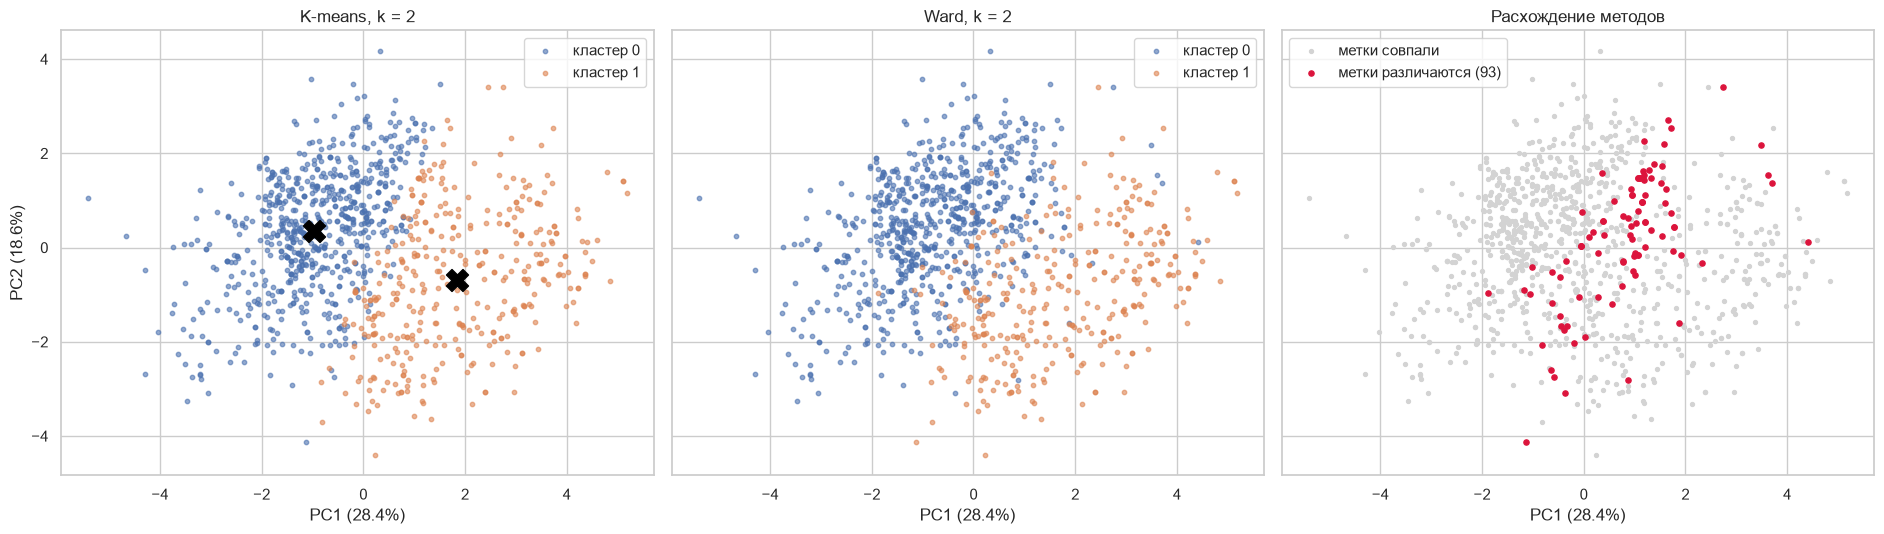

In [22]:
pal = {0: "#4C72B0", 1: "#DD8452"}
cent_km_pca = pca_full.transform(np.vstack([X_scaled[labels_km == c].mean(0) for c in [0, 1]]))[:, :2]
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5), sharex=True, sharey=True)
for ax, lab, title in [(axes[0], labels_km, "K-means, k = 2"), (axes[1], labels_hc, "Ward, k = 2")]:
    for c in [0, 1]:
        ax.scatter(X_pca[lab == c, 0], X_pca[lab == c, 1], s=10, alpha=0.6, color=pal[c], label=f"кластер {c}")
    ax.set_title(title); ax.legend()
axes[0].scatter(cent_km_pca[:, 0], cent_km_pca[:, 1], marker="X", s=250, c="black", label="центры")
diff = labels_km != labels_hc
axes[2].scatter(X_pca[~diff, 0], X_pca[~diff, 1], s=8, color="lightgray", label="метки совпали")
axes[2].scatter(X_pca[diff, 0], X_pca[diff, 1], s=14, color="crimson", label=f"метки различаются ({diff.sum()})")
axes[2].set_title("Расхождение методов"); axes[2].legend()
for ax in axes:
    ax.set_xlabel(f"PC1 ({ev[0]:.1%})")
axes[0].set_ylabel(f"PC2 ({ev[1]:.1%})")
plt.tight_layout()
plt.show()

В плоскости главных компонент оба метода делят облако точек в основном по первой компоненте, то есть по кислотной оси: кластер 0 занимает область отрицательных PC1, кластер 1 – положительных. Граница проходит не строго перпендикулярно PC1, а немного наклонно: кластер 1 смещён также в сторону отрицательных PC2, что соответствует большему содержанию спирта и меньшему содержанию диоксида серы. Центры K-means расположены в точках примерно (−1.0; 0.3) и (1.8; −0.7). Граница пересекает область высокой плотности объектов, что согласуется с малым минимальным расстоянием между кластерами (0.71).

Объекты, на которых методы расходятся (93 вина, отмечены красным), лежат вдоль этой границы, преимущественно в области PC1 ≈ 0.5–2 и положительных PC2. Метод Уорда относит эти вина с умеренно высокой кислотностью, но повышенным диоксидом серы и пониженным спиртом к кластеру 0. Поэтому его кластер 1 меньше и состоит из вин с более высоким содержанием спирта (медиана 11.0 % против 10.8 % у K-means), чем и объясняется чуть лучшее согласие метода Уорда с оценкой качества.

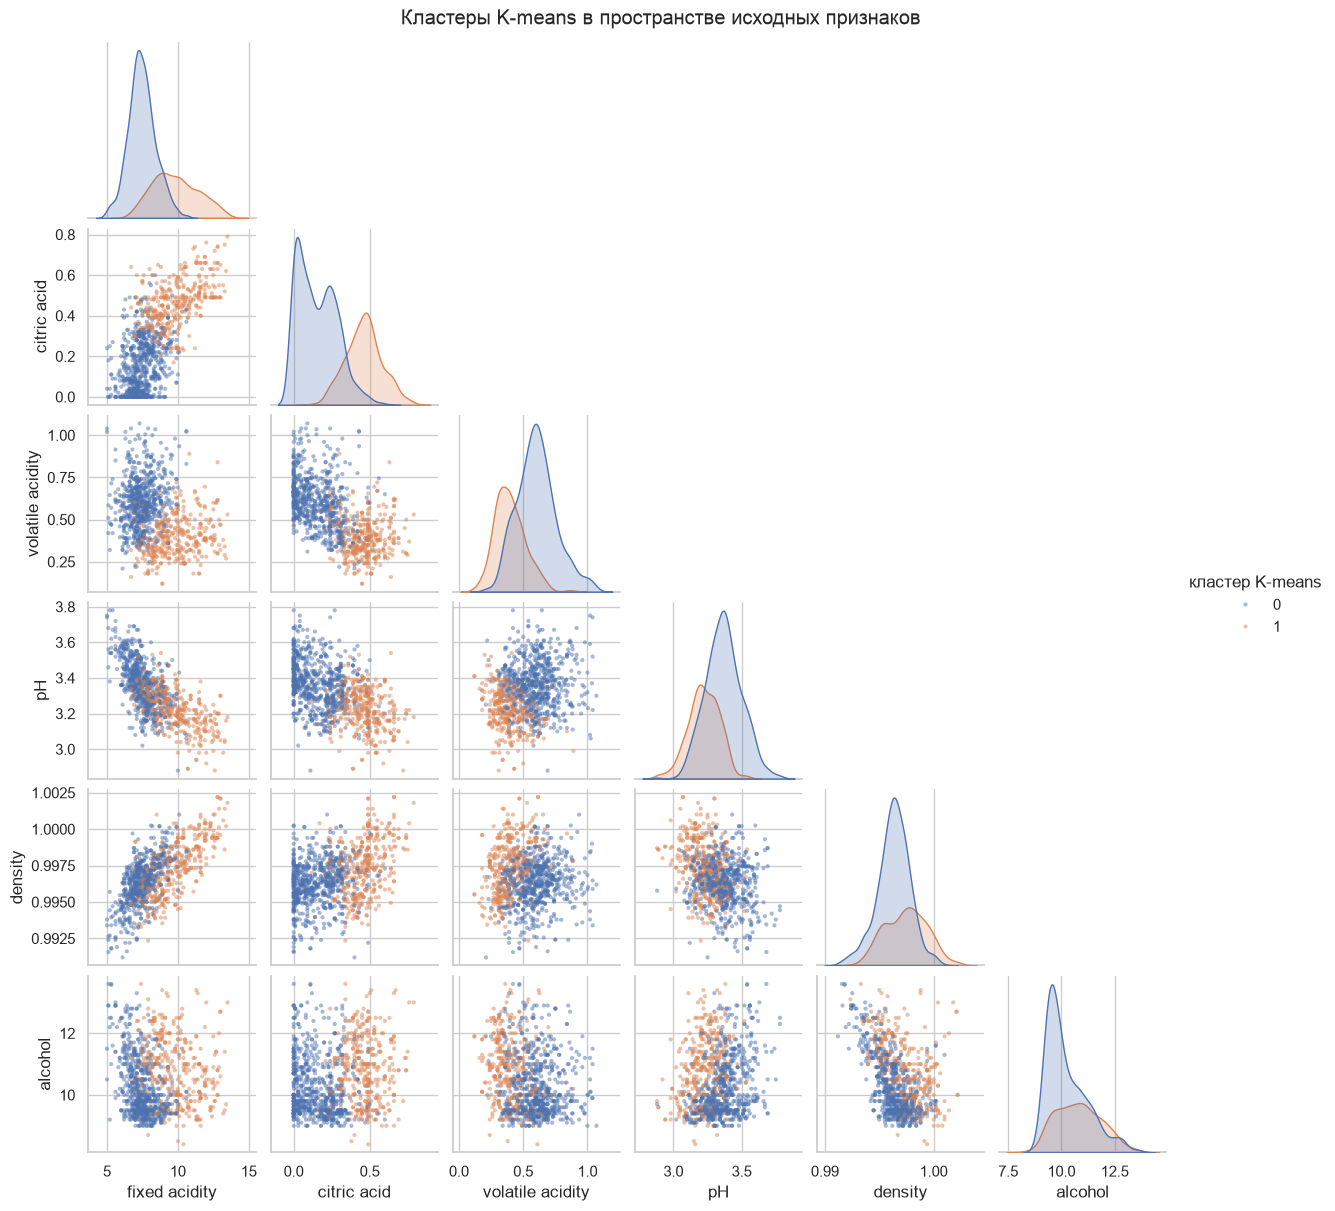

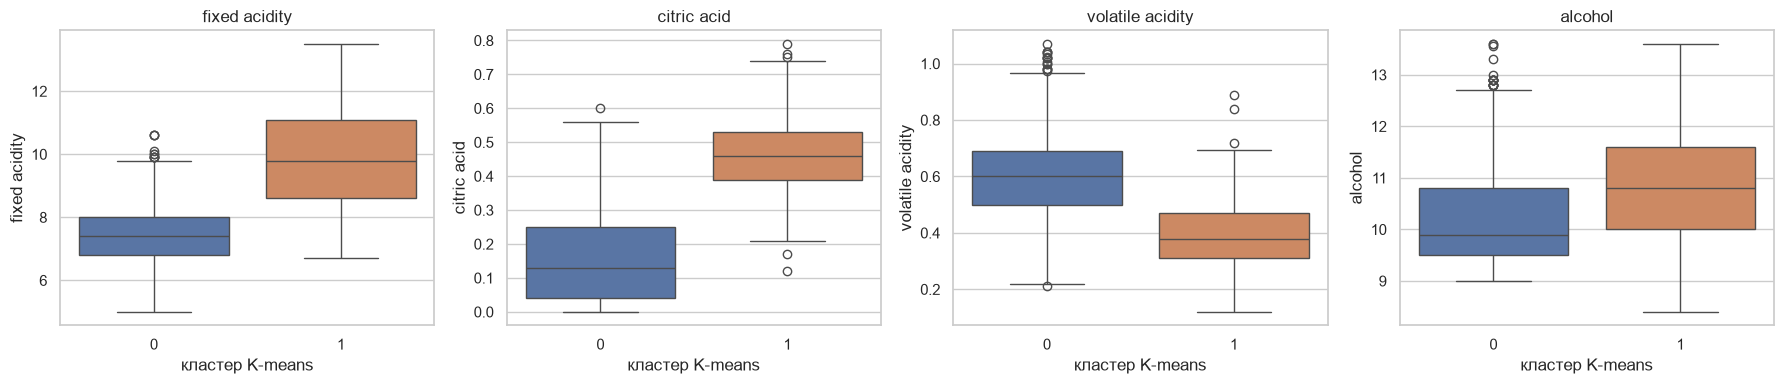

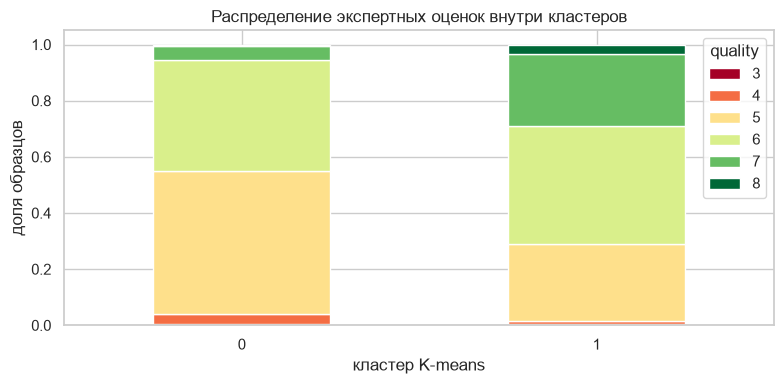

In [23]:
VIS = ["fixed acidity", "citric acid", "volatile acidity", "pH", "density", "alcohol"]
plot_df = X_clean_raw[VIS].copy()
plot_df["кластер K-means"] = labels_km
g = sns.pairplot(plot_df, hue="кластер K-means", palette=pal, corner=True, diag_kind="kde",
                 plot_kws={"s": 9, "alpha": 0.5, "edgecolor": "none"}, height=2.0)
g.figure.suptitle("Кластеры K-means в пространстве исходных признаков", y=1.01)
plt.show()

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, ["fixed acidity", "citric acid", "volatile acidity", "alcohol"]):
    sns.boxplot(x=labels_km, y=X_clean_raw[col], hue=labels_km, palette=pal, ax=ax, legend=False)
    ax.set_xlabel("кластер K-means"); ax.set_title(col)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
pd.crosstab(labels_km, y_quality, normalize="index").plot.bar(stacked=True, ax=ax, colormap="RdYlGn", rot=0)
ax.set_xlabel("кластер K-means"); ax.set_ylabel("доля образцов"); ax.legend(title="quality", bbox_to_anchor=(1, 1))
ax.set_title("Распределение экспертных оценок внутри кластеров")
plt.tight_layout()
plt.show()

В пространстве исходных признаков кластеры лучше всего разделяются по фиксированной кислотности и лимонной кислоте: на диаграмме «fixed acidity – citric acid» группы занимают разные области с небольшим перекрытием, а распределения лимонной кислоты по кластерам почти не пересекаются. Хорошо различаются кластеры также по летучей кислотности и pH. По спирту и плотности распределения кластеров сильно перекрываются, хотя кластер 1 смещён в сторону большего содержания спирта.

Столбчатая диаграмма показывает, что в кластере 1 заметно выше доля оценок 7 и 8, а в кластере 0 преобладают оценки 5.

,0,1,2
fixed acidity,7.100,7.950,10.000
volatile acidity,0.600,0.560,0.380
citric acid,0.070,0.250,0.480
residual sugar,2.000,2.300,2.300
chlorides,0.075,0.082,0.079
free sulfur dioxide,11.000,21.000,7.000
total sulfur dioxide,28.000,67.000,22.000
density,0.996,0.997,0.998
pH,3.390,3.300,3.210
sulphates,0.590,0.600,0.695


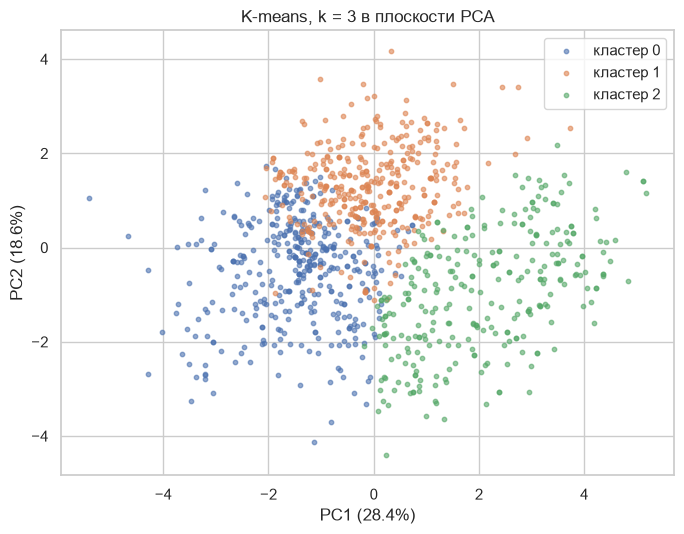

In [24]:
# Дополнительно: более детальное разбиение k = 3 (второй локальный кандидат по CH и дендрограмме)
labels_km3 = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit_predict(X_scaled)
order = pd.Series(X_clean_raw["fixed acidity"]).groupby(labels_km3).mean().sort_values().index
remap = {old: new for new, old in enumerate(order)}
labels_km3 = np.vectorize(remap.get)(labels_km3)
prof3 = X_clean_raw.groupby(labels_km3).median().T
prof3.loc["quality (среднее)"] = y_quality.groupby(labels_km3).mean()
prof3.loc["n"] = np.bincount(labels_km3)
prof3.loc["доля quality ≥ 6"] = (y_quality >= 6).groupby(labels_km3).mean()
display(prof3.round(3))
fig, ax = plt.subplots(figsize=(7, 5.5))
for c, col in zip(range(3), ["#4C72B0", "#DD8452", "#55A868"]):
    ax.scatter(X_pca[labels_km3 == c, 0], X_pca[labels_km3 == c, 1], s=10, alpha=0.6, color=col, label=f"кластер {c}")
ax.set_xlabel(f"PC1 ({ev[0]:.1%})"); ax.set_ylabel(f"PC2 ({ev[1]:.1%})"); ax.legend()
ax.set_title("K-means, k = 3 в плоскости PCA")
plt.tight_layout()
plt.show()

Разбиение на три кластера (k = 3) даёт более детальную и содержательно интересную картину. Кислотный «полюс» сохраняется (кластер 2), а бывший кластер 0 разделяется по оси диоксида серы и спирта (PC2):

- кластер 0 (401 вино) – «лёгкие» вина с низкой кислотностью: почти нет лимонной кислоты (0.07 г/дм³), мало диоксида серы (общий – 28 мг/дм³), умеренный спирт (10.5 %). Средняя оценка 5.61, доля оценок ≥ 6 – 55 %;
- кластер 1 (366 вин) – вина с высоким содержанием диоксида серы (свободный – 21, общий – 67 мг/дм³) и низким содержанием спирта (9.7 %). Это самая «слабая» группа: средняя оценка 5.38, доля оценок ≥ 6 всего 37 %. Повышенное сульфитирование обычно применяется для стабилизации менее качественного сырья, а низкий спирт – признак менее зрелого винограда;
- кластер 2 (290 вин) – «структурные» вина с высокой кислотностью (10.0 г/дм³), высокой долей лимонной кислоты (0.48 г/дм³), низкой летучей кислотностью (0.38 г/дм³), высокими сульфатами (0.70 г/дм³) и спиртом (10.9 %). Средняя оценка 6.07, доля оценок ≥ 6 – 75 %.

Это разбиение хуже по внутренним метрикам (силуэт 0.149) и менее устойчиво, однако даёт полезную для практики типологию: оно отделяет группу вин, для которой вероятность низкой оценки наиболее высока.

In [25]:
summary = pd.DataFrame({
    "K-means (k=2)": [*metrics["K-means (k=2)"][["Силуэт ↑", "Calinski–Harabasz ↑", "Davies–Bouldin ↓",
                                                 "Adjusted Rand ↑", "Jaccard (пары) ↑", "NMI ↑"]],
                      kmeans.inertia_],
    "Ward (k=2)": [*metrics["Ward (k=2)"][["Силуэт ↑", "Calinski–Harabasz ↑", "Davies–Bouldin ↓",
                                           "Adjusted Rand ↑", "Jaccard (пары) ↑", "NMI ↑"]],
                   sum(((X_scaled[labels_hc == c] - X_scaled[labels_hc == c].mean(0)) ** 2).sum() for c in [0, 1])],
}, index=["Силуэт", "Calinski–Harabasz", "Davies–Bouldin", "ARI (quality ≥ 6)", "Jaccard (quality ≥ 6)",
          "NMI (quality ≥ 6)", "WCSS"])
display(summary.round(3))

,K-means (k=2),Ward (k=2)
Силуэт,0.204,0.198
Calinski–Harabasz,247.289,219.319
Davies–Bouldin,1.909,1.966
ARI (quality ≥ 6),0.042,0.068
Jaccard (quality ≥ 6),0.374,0.395
NMI (quality ≥ 6),0.047,0.081
WCSS,9419.171,9625.915


### Сравнительная таблица метрик качества

| Метрика | K-means (k = 2) | Ward (k = 2) | Лучше |
|---|---|---|---|
| Силуэт ↑ | 0.204 | 0.198 | K-means |
| Calinski–Harabasz ↑ | 247.3 | 219.3 | K-means |
| Davies–Bouldin ↓ | 1.909 | 1.966 | K-means |
| WCSS ↓ | 9 419 | 9 626 | K-means |
| ARI (quality ≥ 6) ↑ | 0.042 | 0.068 | Ward |
| Jaccard (quality ≥ 6) ↑ | 0.374 | 0.395 | Ward |
| NMI (quality ≥ 6) ↑ | 0.047 | 0.081 | Ward |
| Устойчивость, ARI на подвыборках 80 % ↑ | 0.935 ± 0.042 | 0.744 ± 0.117 | K-means |
| Время / сложность | O(n·k·I), быстро | O(n²) по памяти | K-means |

K-means выигрывает по всем внутренним метрикам и значительно устойчивее к изменению выборки, а метод Уорда – по всем внешним метрикам. Это классическое для кластерного анализа противоречие: внутренние метрики оценивают геометрическую компактность и отделимость кластеров, которую K-means оптимизирует напрямую, а внешние – совпадение с разметкой, которая не обязана соответствовать оптимальной геометрии. Ни один из методов не является лучшим «по всем показателям», и выбор зависит от цели анализа. При этом метод Уорда согласуется с оценкой качества лишь немного лучше, однако абсолютные значения внешних метрик у обоих методов малы, а различие между ними сопоставимо с разбросом, возникающим при изменении выборки. Оба метода выделили по сути одни и те же группы (совпадение 91 % объектов), поэтому найденная структура определяется данными, а не особенностями алгоритма.

## 6. Заключение

В работе проведён кластерный анализ 1 057 образцов красного вина по 11 физико-химическим признакам (после логарифмирования асимметричных признаков и удаления 86 выбросов).

1. Применимость кластеризации. Статистика Хопкинса H = 0.79 (против 0.50 для равномерного шума) показала, что данные склонны к кластеризации, но структура выражена умеренно. Это подтвердили все последующие метрики: силуэт около 0.2, DB > 1, минимальное расстояние между кластерами много меньше их радиуса. Кластеры в данных существуют, но пересекаются и не разделены зонами низкой плотности.
2. Число кластеров. Метод локтя не дал однозначного ответа (изгиб в области k = 3–5), тогда как силуэтный анализ, индекс Calinski–Harabasz и дендрограмма Уорда согласованно указали на k = 2. Это пример того, что для данных с размытой структурой метод локтя следует дополнять другими критериями.
3. Сравнение методов. K-means и метод Уорда выделили практически одинаковые группы (совпадение 91.2 %, ARI 0.67). K-means превосходит метод Уорда по силуэту (0.204 против 0.198), CH (247 против 219), DB (1.91 против 1.97), WCSS и, главное, по устойчивости к изменению выборки (ARI 0.94 против 0.74). Метод Уорда, напротив, лучше по всем внешним метрикам (ARI 0.068 против 0.042), что отражает типичное противоречие между внутренними и внешними критериями; кроме того, он даёт дендрограмму, полезную для выбора числа кластеров. Методы с одиночной и средней связью на этих данных вырождаются, а высокий силуэт для них вводит в заблуждение.
4. Влияние параметров. Увеличение k ухудшает внутренние метрики, но при k = 4–5 растёт согласие с качеством вина. Несколько перезапусков K-means (`n_init=10`) практически не нужны при k = 2, но критически важны при k ≥ 3, где единичный запуск воспроизводит лучшее решение лишь с ARI 0.64–0.73.
5. Интерпретация. Главная ось различий – кислотный профиль вина. Выделены группа «мягких» вин с низкой фиксированной кислотностью, почти без лимонной кислоты, с повышенной летучей кислотностью и диоксидом серы (средняя оценка 5.47) и группа «структурных» вин с высокой кислотностью, лимонной кислотой, сульфатами и спиртом (средняя оценка 6.01–6.11, 71–78 % оценок ≥ 6). При k = 3 дополнительно выделяется группа сильно сульфитированных вин с низким содержанием спирта, имеющая наименьшую среднюю оценку (5.38).
6. Применимость методов. Для данных этого типа (непрерывные признаки, выпуклые пересекающиеся кластеры без пустот) лучше всего подходят методы, минимизирующие внутрикластерную дисперсию: K-means как основной метод и иерархическая кластеризация Уорда как средство проверки числа кластеров. Плотностные методы (DBSCAN) и методы одиночной связи неприменимы из-за отсутствия областей низкой плотности. Внешние метрики (ARI ≈ 0.04–0.07) показывают, что химический состав объясняет экспертную оценку лишь частично, поэтому кластеризацию разумно использовать для типологии вин и разведочного анализа, а не как замену модели классификации качества.

## 7. Список источников

1. Cortez P., Cerdeira A., Almeida F., Matos T., Reis J. Modeling wine preferences by data mining from physicochemical properties // Decision Support Systems. 2009. Vol. 47, No. 4. P. 547–553.
2. Wine Quality Dataset [Электронный ресурс] // Kaggle. URL: https://www.kaggle.com/datasets/yasserh/wine-quality-dataset (дата обращения: 23.11.2026).
3. Kaufman L., Rousseeuw P. J. Finding Groups in Data: An Introduction to Cluster Analysis. New York: Wiley, 1990. 342 p.; Rousseeuw P. J. Silhouettes: a graphical aid to the interpretation and validation of cluster analysis // Journal of Computational and Applied Mathematics. 1987. Vol. 20. P. 53–65.
4. Caliński T., Harabasz J. A dendrite method for cluster analysis // Communications in Statistics. 1974. Vol. 3, No. 1. P. 1–27.
5. Davies D. L., Bouldin D. W. A cluster separation measure // IEEE Transactions on Pattern Analysis and Machine Intelligence. 1979. Vol. PAMI-1, No. 2. P. 224–227.
6. Hubert L., Arabie P. Comparing partitions // Journal of Classification. 1985. Vol. 2. P. 193–218.
7. Ward J. H. Hierarchical grouping to optimize an objective function // Journal of the American Statistical Association. 1963. Vol. 58, No. 301. P. 236–244.
8. Lawson R. G., Jurs P. C. New index for clustering tendency and its application to chemical problems // Journal of Chemical Information and Computer Sciences. 1990. Vol. 30, No. 1. P. 36–41.
9. Arthur D., Vassilvitskii S. k-means++: the advantages of careful seeding // Proceedings of the 18th Annual ACM-SIAM Symposium on Discrete Algorithms. 2007. P. 1027–1035.
10. Jain A. K. Data clustering: 50 years beyond K-means // Pattern Recognition Letters. 2010. Vol. 31, No. 8. P. 651–666.
11. Hastie T., Tibshirani R., Friedman J. The Elements of Statistical Learning: Data Mining, Inference, and Prediction. 2nd ed. New York: Springer, 2009. 745 p.
12. Мандель И. Д. Кластерный анализ. М.: Финансы и статистика, 1988. 176 с.
13. Scikit-learn: Clustering [Электронный ресурс]. URL: https://scikit-learn.org/stable/modules/clustering.html (дата обращения: 23.11.2026).
14. Scikit-learn: Clustering performance evaluation [Электронный ресурс]. URL: https://scikit-learn.org/stable/modules/clustering.html#clustering-performance-evaluation (дата обращения: 23.11.2026).
15. SciPy: Hierarchical clustering (scipy.cluster.hierarchy) [Электронный ресурс]. URL: https://docs.scipy.org/doc/scipy/reference/cluster.hierarchy.html (дата обращения: 23.11.2026).

## 8. Приложение. Полный листинг программного кода

Ниже приведён код всех вычислительных ячеек ноутбука в порядке их выполнения. Используемые библиотеки: pandas, numpy, scipy, scikit-learn, matplotlib, seaborn. Данные: `data/WineQT.csv`.

```python
%matplotlib inline
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from scipy.spatial.distance import cdist, pdist

from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import (
    silhouette_score, silhouette_samples, calinski_harabasz_score, davies_bouldin_score,
    rand_score, adjusted_rand_score, normalized_mutual_info_score, adjusted_mutual_info_score,
    fowlkes_mallows_score, homogeneity_completeness_v_measure,
)
from sklearn.metrics.cluster import pair_confusion_matrix, contingency_matrix

warnings.filterwarnings("ignore")
SEED = 42
pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100

df = pd.read_csv("data/WineQT.csv")
print("Размерность исходной таблицы:", df.shape)
display(df.head())

FEATURES = [c for c in df.columns if c not in ("quality", "Id")]
X_raw = df[FEATURES].copy()
quality = df["quality"].copy()

info = pd.DataFrame({
    "тип": X_raw.dtypes.astype(str),
    "пропуски": X_raw.isna().sum(),
    "уникальных": X_raw.nunique(),
})
display(info)
print("Пропусков всего:", int(df.isna().sum().sum()))
print("Полных дубликатов по физико-химическим признакам:", int(X_raw.duplicated().sum()))
print("Распределение оценок качества:", quality.value_counts().sort_index().to_dict())

desc = X_raw.describe().T
desc["CV, %"] = 100 * desc["std"] / desc["mean"]
desc["асимметрия"] = X_raw.skew()
desc["эксцесс"] = X_raw.kurt()
desc["p (D'Agostino)"] = [stats.normaltest(X_raw[c]).pvalue for c in FEATURES]
display(desc[["mean", "std", "min", "25%", "50%", "75%", "max", "CV, %", "асимметрия", "эксцесс", "p (D'Agostino)"]])

fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col in zip(axes.flat, FEATURES):
    sns.histplot(X_raw[col], bins=35, kde=True, ax=ax, color="#4C72B0", stat="density")
    mu, sd = X_raw[col].mean(), X_raw[col].std()
    xs = np.linspace(X_raw[col].min(), X_raw[col].max(), 200)
    ax.plot(xs, stats.norm.pdf(xs, mu, sd), "r--", lw=1.2, label="N(μ, σ)")
    ax.set_title(f"{col}\nasym = {X_raw[col].skew():.2f}", fontsize=10)
    ax.set_xlabel("")
axes.flat[0].legend(fontsize=8)
axes.flat[-1].axis("off")
fig.suptitle("Распределения исходных признаков (красная линия – нормальное распределение с теми же μ и σ)", y=1.0)
plt.tight_layout()
plt.show()

corr = X_raw.corr(method="spearman")
fig, axes = plt.subplots(1, 2, figsize=(17, 6.5), gridspec_kw={"width_ratios": [1.25, 1]})
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=axes[0],
            annot_kws={"size": 8}, cbar_kws={"shrink": 0.8})
axes[0].set_title("Корреляции Спирмена между признаками")

mi = pd.Series(mutual_info_classif(X_raw, quality, random_state=SEED), index=FEATURES)
signif = pd.DataFrame({
    "CV, %": desc["CV, %"],
    "max |r| с другими": corr.abs().where(~np.eye(len(FEATURES), dtype=bool)).max(),
    "MI с quality": mi,
}).sort_values("MI с quality", ascending=False)
signif["MI с quality"].plot.barh(ax=axes[1], color="#55A868")
axes[1].invert_yaxis()
axes[1].set_title("Взаимная информация признаков с оценкой quality")
axes[1].set_xlabel("MI, нат")
plt.tight_layout()
plt.show()
display(signif)

q1, q3 = X_raw.quantile(0.25), X_raw.quantile(0.75)
iqr = q3 - q1
iqr_mask = (X_raw < q1 - 1.5 * iqr) | (X_raw > q3 + 1.5 * iqr)
z_mask = pd.DataFrame(np.abs(stats.zscore(X_raw)) > 3, columns=FEATURES)
outl = pd.DataFrame({"IQR (1.5)": iqr_mask.sum(), "|z| > 3": z_mask.sum()})
display(outl.T)
print("Строк хотя бы с одним выбросом по IQR:", int(iqr_mask.any(axis=1).sum()),
      f"({iqr_mask.any(axis=1).mean():.1%})")
print("Строк хотя бы с одним выбросом по |z| > 3:", int(z_mask.any(axis=1).sum()),
      f"({z_mask.any(axis=1).mean():.1%})")

Xs_tmp = StandardScaler().fit_transform(X_raw)
fig, ax = plt.subplots(figsize=(14, 4.5))
sns.boxplot(data=pd.DataFrame(Xs_tmp, columns=FEATURES), ax=ax, color="#8DA0CB", fliersize=2)
ax.set_title("Диаграммы размаха исходных признаков (z-оценки)")
ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

# как выбросы влияют на K-means, если их не обрабатывать
for k in [4, 5, 6]:
    sizes = np.bincount(KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(Xs_tmp))
    print(f"K-means на сырых данных, k = {k}: размеры кластеров {sorted(sizes.tolist())}")

SKEWED = ["residual sugar", "chlorides", "free sulfur dioxide", "total sulfur dioxide", "sulphates"]
X_log = X_raw.copy()
X_log[SKEWED] = np.log1p(X_log[SKEWED])

z_log = np.abs(stats.zscore(X_log))
keep = (z_log <= 3).all(axis=1)
print("Удалено наблюдений с |z| > 3 после логарифмирования:", int((~keep).sum()),
      f"({(~keep).mean():.1%})")

X_clean_raw = X_raw[keep].reset_index(drop=True)     # исходные единицы – для интерпретации центров
X_clean = X_log[keep].reset_index(drop=True)         # пространство кластеризации
y_quality = quality[keep].reset_index(drop=True)
print("Размер очищенной выборки:", X_clean.shape)

skew_cmp = pd.DataFrame({
    "асимметрия: исходные": X_raw.skew(),
    "после log1p и очистки": X_clean.skew(),
})
display(skew_cmp.T)

fig, axes = plt.subplots(1, 5, figsize=(18, 3.4))
for ax, col in zip(axes, SKEWED):
    sns.histplot(X_clean[col], bins=30, kde=True, ax=ax, color="#C44E52")
    ax.set_title(f"log1p({col})\nasym = {X_clean[col].skew():.2f}", fontsize=10)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

def hopkins(X, frac=0.1, seed=SEED):
    """Статистика Хопкинса H = Σu / (Σu + Σw): u – расстояния от равномерно
    распределённых точек до ближайшего объекта выборки, w – от объектов выборки
    до их ближайшего соседа. H ≈ 0.5 – случайные данные, H → 1 – выраженная кластерность."""
    rng = np.random.default_rng(seed)
    X = np.asarray(X)
    n, m = len(X), int(frac * len(X))
    nn = NearestNeighbors(n_neighbors=2).fit(X)
    w = nn.kneighbors(X[rng.choice(n, m, replace=False)], 2)[0][:, 1]
    U = rng.uniform(X.min(0), X.max(0), (m, X.shape[1]))
    u = nn.kneighbors(U, 1)[0][:, 0]
    return u.sum() / (u.sum() + w.sum())

Xh = StandardScaler().fit_transform(X_clean)
H = [hopkins(Xh, seed=s) for s in range(20)]
rng = np.random.default_rng(SEED)
H_unif = [hopkins(rng.uniform(Xh.min(0), Xh.max(0), Xh.shape), seed=s) for s in range(20)]
print(f"Хопкинс, данные:            {np.mean(H):.3f} ± {np.std(H):.3f}")
print(f"Хопкинс, равномерный шум:   {np.mean(H_unif):.3f} ± {np.std(H_unif):.3f}")

scalers = {"StandardScaler": StandardScaler(), "MinMaxScaler": MinMaxScaler(), "RobustScaler": RobustScaler()}
rows = []
for name, sc in scalers.items():
    Z = sc.fit_transform(X_clean)
    lab = KMeans(n_clusters=2, n_init=10, random_state=SEED).fit_predict(Z)
    spread = Z.std(axis=0)
    rows.append({
        "метод": name,
        "разброс σ признаков (min–max)": f"{spread.min():.2f}–{spread.max():.2f}",
        "силуэт (k=2)": silhouette_score(Z, lab),
        "CH (k=2)": calinski_harabasz_score(Z, lab),
        "размеры кластеров": sorted(np.bincount(lab).tolist()),
    })
display(pd.DataFrame(rows).set_index("метод"))

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_clean)
X_scaled_df = pd.DataFrame(X_scaled, columns=FEATURES)
display(X_scaled_df.describe().T[["mean", "std", "min", "max"]].round(3))

PAIR = ["fixed acidity", "volatile acidity", "citric acid", "density", "pH", "sulphates", "alcohol",
        "total sulfur dioxide"]
g = sns.pairplot(X_scaled_df[PAIR], corner=True, diag_kind="kde",
                 plot_kws={"s": 8, "alpha": 0.45, "edgecolor": "none"}, height=1.85)
g.figure.suptitle("Матрица диаграмм рассеивания (стандартизованные признаки)", y=1.01)
plt.show()

pca_full = PCA(random_state=SEED).fit(X_scaled)
ev = pca_full.explained_variance_ratio_
X_pca = pca_full.transform(X_scaled)[:, :2]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(range(1, 12), ev, color="#4C72B0", label="доля дисперсии")
axes[0].plot(range(1, 12), np.cumsum(ev), "o-", color="#C44E52", label="накопленная доля")
axes[0].set_xlabel("номер главной компоненты"); axes[0].set_xticks(range(1, 12)); axes[0].legend()
axes[0].set_title("Объяснённая дисперсия PCA")
axes[1].hexbin(X_pca[:, 0], X_pca[:, 1], gridsize=35, cmap="Blues", mincnt=1)
axes[1].set_xlabel(f"PC1 ({ev[0]:.1%})"); axes[1].set_ylabel(f"PC2 ({ev[1]:.1%})")
axes[1].set_title("Плотность объектов в плоскости PC1–PC2")
plt.tight_layout()
plt.show()
print("Накопленная доля дисперсии первых 2/3/5 компонент:", np.cumsum(ev)[[1, 2, 4]].round(3))
loadings = pd.DataFrame(pca_full.components_[:3].T, index=FEATURES, columns=["PC1", "PC2", "PC3"])
display(loadings.round(3))

K_RANGE = range(2, 11)
rows = []
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X_scaled)
    ag = AgglomerativeClustering(n_clusters=k, linkage="ward").fit(X_scaled)
    rows.append({
        "k": k, "WCSS (inertia)": km.inertia_,
        "силуэт KM": silhouette_score(X_scaled, km.labels_),
        "CH KM": calinski_harabasz_score(X_scaled, km.labels_),
        "DB KM": davies_bouldin_score(X_scaled, km.labels_),
        "силуэт Ward": silhouette_score(X_scaled, ag.labels_),
        "CH Ward": calinski_harabasz_score(X_scaled, ag.labels_),
        "DB Ward": davies_bouldin_score(X_scaled, ag.labels_),
    })
k_tab = pd.DataFrame(rows).set_index("k")
# второй разностный критерий для «локтя»
k_tab["Δ² WCSS"] = k_tab["WCSS (inertia)"].diff().diff().shift(-1)
display(k_tab)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].plot(k_tab.index, k_tab["WCSS (inertia)"], "o-")
axes[0].set_title("Метод локтя (K-means)"); axes[0].set_xlabel("k"); axes[0].set_ylabel("WCSS")
axes[1].plot(k_tab.index, k_tab["силуэт KM"], "o-", label="K-means")
axes[1].plot(k_tab.index, k_tab["силуэт Ward"], "s--", label="Ward")
axes[1].set_title("Средний коэффициент силуэта"); axes[1].set_xlabel("k"); axes[1].legend()
axes[2].plot(k_tab.index, k_tab["CH KM"], "o-", label="CH, K-means")
axes[2].plot(k_tab.index, k_tab["CH Ward"], "s--", label="CH, Ward")
ax2 = axes[2].twinx()
ax2.plot(k_tab.index, k_tab["DB KM"], "^:", color="gray", label="DB, K-means")
axes[2].set_title("Calinski–Harabasz (слева) и Davies–Bouldin (справа)"); axes[2].set_xlabel("k")
axes[2].legend(loc="upper center"); ax2.legend(loc="center right"); ax2.grid(False)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharex=True)
for ax, k in zip(axes, [2, 3, 4]):
    lab = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(X_scaled)
    s = silhouette_samples(X_scaled, lab)
    y0 = 10
    for c in range(k):
        sc = np.sort(s[lab == c])
        ax.fill_betweenx(np.arange(y0, y0 + len(sc)), 0, sc, alpha=0.8, color=sns.color_palette("Set2")[c])
        ax.text(-0.08, y0 + len(sc) / 2, str(c))
        y0 += len(sc) + 10
    ax.axvline(s.mean(), color="red", ls="--")
    ax.set_title(f"k = {k}: средний силуэт {s.mean():.3f}, доля s<0: {(s < 0).mean():.1%}")
    ax.set_yticks([]); ax.set_xlabel("коэффициент силуэта")
plt.tight_layout()
plt.show()

Z_ward = linkage(X_scaled, method="ward")
cut2 = (Z_ward[-1, 2] + Z_ward[-2, 2]) / 2        # уровень разреза, дающий два кластера
fig, axes = plt.subplots(1, 2, figsize=(17, 5), gridspec_kw={"width_ratios": [2.2, 1]})
dendrogram(Z_ward, truncate_mode="lastp", p=40, show_leaf_counts=True, leaf_rotation=90,
           leaf_font_size=8, ax=axes[0], color_threshold=cut2)
axes[0].axhline(cut2, color="red", ls="--", lw=1, label="разрез на k = 2")
axes[0].legend()
axes[0].set_title("Дендрограмма (метод Уорда, последние 40 слияний)")
axes[0].set_ylabel("расстояние слияния")
last = Z_ward[-12:, 2][::-1]
axes[1].plot(range(2, 14), last, "o-")
axes[1].set_xticks(range(2, 14))
axes[1].set_title("Высоты последних 12 слияний")
axes[1].set_xlabel("k – число кластеров при разрезе чуть ниже слияния")
plt.tight_layout()
plt.show()
gaps = pd.Series(-np.diff(last), index=[f"k = {k}" for k in range(2, 13)])
print("Ширина интервала высот, в котором разрез даёт k кластеров:")
print(gaps.round(2).head(6).to_string())

K_OPT = 2
kmeans = KMeans(n_clusters=K_OPT, n_init=10, random_state=SEED).fit(X_scaled)
labels_km = kmeans.labels_
ward = AgglomerativeClustering(n_clusters=K_OPT, linkage="ward").fit(X_scaled)
labels_hc = ward.labels_

# согласуем номера: кластер 1 – группа с более высокой фиксированной кислотностью
def align(lab):
    m = pd.Series(X_clean["fixed acidity"]).groupby(lab).mean()
    return lab if m[1] > m[0] else 1 - lab
labels_km, labels_hc = align(labels_km), align(labels_hc)

print("Размеры кластеров K-means:", np.bincount(labels_km))
print("Размеры кластеров Ward:   ", np.bincount(labels_hc))
print("Число итераций K-means:", kmeans.n_iter_, " | инерция:", round(kmeans.inertia_, 1))
cross = pd.crosstab(pd.Series(labels_km, name="K-means"), pd.Series(labels_hc, name="Ward"))
display(cross)
print(f"Совпадение меток двух методов: {(labels_km == labels_hc).mean():.1%}, "
      f"ARI между методами: {adjusted_rand_score(labels_km, labels_hc):.3f}")

def jaccard_pairs(a, b):
    (tn, fp), (fn, tp) = pair_confusion_matrix(a, b)
    return tp / (tp + fp + fn)

def purity(y, lab):
    cm = contingency_matrix(y, lab)
    return cm.max(axis=0).sum() / cm.sum()

y_bin = (y_quality >= 6).astype(int).values   # «хорошее» (≥ 6) / «обычное» (≤ 5)

def all_metrics(lab):
    h, c, v = homogeneity_completeness_v_measure(y_bin, lab)
    return {
        "Силуэт ↑": silhouette_score(X_scaled, lab),
        "Calinski–Harabasz ↑": calinski_harabasz_score(X_scaled, lab),
        "Davies–Bouldin ↓": davies_bouldin_score(X_scaled, lab),
        "Rand index ↑": rand_score(y_bin, lab),
        "Adjusted Rand ↑": adjusted_rand_score(y_bin, lab),
        "Jaccard (пары) ↑": jaccard_pairs(y_bin, lab),
        "Fowlkes–Mallows ↑": fowlkes_mallows_score(y_bin, lab),
        "NMI ↑": normalized_mutual_info_score(y_bin, lab),
        "Homogeneity ↑": h, "Completeness ↑": c,
        "Purity ↑": purity(y_bin, lab),
    }

metrics = pd.DataFrame({"K-means (k=2)": all_metrics(labels_km), "Ward (k=2)": all_metrics(labels_hc)})
# опорные значения: случайное разбиение тех же размеров
rng = np.random.default_rng(SEED)
metrics["случайные метки"] = pd.DataFrame(
    [all_metrics(rng.permutation(labels_km)) for _ in range(20)]).mean()
display(metrics.round(3))

for name, lab in [("K-means", labels_km), ("Ward", labels_hc)]:
    ct = pd.crosstab(pd.Series(lab, name=f"кластер {name}"), y_quality.rename("quality"))
    ct["доля quality ≥ 6"] = (ct[[6, 7, 8]].sum(axis=1) / ct.sum(axis=1)).round(3)
    display(ct)

def cluster_geometry(X, lab):
    ks = np.unique(lab)
    centers = np.vstack([X[lab == c].mean(0) for c in ks])
    rows = []
    for c in ks:
        P = X[lab == c]
        d_c = np.linalg.norm(P - centers[c], axis=1)
        rows.append({
            "кластер": c, "n": len(P),
            "ср. расст. до центра": d_c.mean(),
            "RMS-радиус": np.sqrt((d_c ** 2).mean()),
            "ср. попарное расст.": pdist(P).mean(),
            "диаметр": pdist(P).max(),
            "WCSS": (d_c ** 2).sum(),
        })
    geo = pd.DataFrame(rows).set_index("кластер")
    D = cdist(X[lab == 0], X[lab == 1])
    between = {
        "между центрами": np.linalg.norm(centers[0] - centers[1]),
        "ближайшие точки (single)": D.min(),
        "среднее (average)": D.mean(),
        "дальние точки (complete)": D.max(),
    }
    return geo, pd.Series(between), centers

for name, lab in [("K-means", labels_km), ("Ward", labels_hc)]:
    geo, between, centers = cluster_geometry(X_scaled, lab)
    print(f"=== {name} ===")
    display(geo.round(3))
    print("Межкластерные расстояния:", between.round(3).to_dict())
    print("Отношение межцентрового расстояния к среднему радиусу:",
          round(between["между центрами"] / geo["ср. расст. до центра"].mean(), 3))

cent_scaled = pd.DataFrame(
    {f"KM {c}": X_scaled[labels_km == c].mean(0) for c in [0, 1]} |
    {f"Ward {c}": X_scaled[labels_hc == c].mean(0) for c in [0, 1]}, index=FEATURES)

cent_raw = pd.DataFrame(
    {f"KM {c}": X_clean_raw[labels_km == c].median() for c in [0, 1]} |
    {f"Ward {c}": X_clean_raw[labels_hc == c].median() for c in [0, 1]} |
    {"вся выборка": X_clean_raw.median()})
cent_raw.loc["quality (среднее)"] = [y_quality[labels_km == 0].mean(), y_quality[labels_km == 1].mean(),
                                     y_quality[labels_hc == 0].mean(), y_quality[labels_hc == 1].mean(),
                                     y_quality.mean()]
print("Центры кластеров в стандартизованном пространстве (средние z-оценки):")
display(cent_scaled.round(2))
print("Медианы признаков по кластерам в исходных единицах:")
display(cent_raw.round(3))

fig, ax = plt.subplots(figsize=(11, 5))
sns.heatmap(cent_scaled.T, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax)
ax.set_title("Профили центров кластеров (средние z-оценки признаков)")
plt.tight_layout()
plt.show()

# 1) влияние k: внутренние и внешние метрики (внешняя – по трём уровням качества)
y3 = pd.cut(y_quality, [0, 5, 6, 10], labels=[0, 1, 2]).astype(int).values   # ≤5 / 6 / ≥7
rows = []
for k in range(2, 11):
    lab = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(X_scaled)
    sizes = np.bincount(lab)
    rows.append({"k": k, "силуэт": silhouette_score(X_scaled, lab),
                 "CH": calinski_harabasz_score(X_scaled, lab), "DB": davies_bouldin_score(X_scaled, lab),
                 "ARI (3 уровня)": adjusted_rand_score(y3, lab),
                 "NMI (3 уровня)": normalized_mutual_info_score(y3, lab),
                 "мин. кластер": sizes.min(), "макс. кластер": sizes.max()})
param_k = pd.DataFrame(rows).set_index("k")
display(param_k.round(3))

# 2) влияние способа инициализации и n_init на итоговую инерцию и устойчивость
rows = []
for k in [2, 3, 4, 6]:
    for init in ["k-means++", "random"]:
        for n_init in [1, 10]:
            runs = [KMeans(n_clusters=k, init=init, n_init=n_init, random_state=s).fit(X_scaled)
                    for s in range(30)]
            inert = np.array([r.inertia_ for r in runs])
            ref = runs[int(inert.argmin())].labels_
            ari = np.array([adjusted_rand_score(ref, r.labels_) for r in runs])
            rows.append({"k": k, "init": init, "n_init": n_init,
                         "инерция min": inert.min(), "инерция mean": inert.mean(),
                         "доля запусков с лучшей инерцией": np.isclose(inert, inert.min(), rtol=1e-6).mean(),
                         "ARI с лучшим решением (mean)": ari.mean()})
init_tab = pd.DataFrame(rows).set_index(["k", "init", "n_init"])
display(init_tab.round(3))

# 3) устойчивость к выборке: бутстреп 80 % объектов, сравнение с решением на полной выборке
def bootstrap_stability(make_model, k, n_boot=30):
    full = make_model(k).fit_predict(X_scaled)
    rng = np.random.default_rng(SEED)
    out = []
    for _ in range(n_boot):
        idx = rng.choice(len(X_scaled), int(0.8 * len(X_scaled)), replace=False)
        sub = make_model(k).fit_predict(X_scaled[idx])
        out.append(adjusted_rand_score(full[idx], sub))
    return np.mean(out), np.std(out)

rows = []
for k in [2, 3, 4, 5]:
    m_km, s_km = bootstrap_stability(lambda k: KMeans(n_clusters=k, n_init=10, random_state=SEED), k)
    m_hc, s_hc = bootstrap_stability(lambda k: AgglomerativeClustering(n_clusters=k, linkage="ward"), k)
    rows.append({"k": k, "K-means ARI": f"{m_km:.3f} ± {s_km:.3f}", "Ward ARI": f"{m_hc:.3f} ± {s_hc:.3f}"})
display(pd.DataFrame(rows).set_index("k"))

# 4) влияние метода связи в иерархической кластеризации (k = 2 и 3)
rows = []
for link in ["ward", "complete", "average", "single"]:
    for k in [2, 3]:
        lab = AgglomerativeClustering(n_clusters=k, linkage=link).fit_predict(X_scaled)
        rows.append({"linkage": link, "k": k, "силуэт": silhouette_score(X_scaled, lab),
                     "CH": calinski_harabasz_score(X_scaled, lab),
                     "размеры": sorted(np.bincount(lab).tolist(), reverse=True),
                     "ARI с K-means": adjusted_rand_score(
                         KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(X_scaled), lab)})
display(pd.DataFrame(rows).set_index(["linkage", "k"]).round(3))

pal = {0: "#4C72B0", 1: "#DD8452"}
cent_km_pca = pca_full.transform(np.vstack([X_scaled[labels_km == c].mean(0) for c in [0, 1]]))[:, :2]
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5), sharex=True, sharey=True)
for ax, lab, title in [(axes[0], labels_km, "K-means, k = 2"), (axes[1], labels_hc, "Ward, k = 2")]:
    for c in [0, 1]:
        ax.scatter(X_pca[lab == c, 0], X_pca[lab == c, 1], s=10, alpha=0.6, color=pal[c], label=f"кластер {c}")
    ax.set_title(title); ax.legend()
axes[0].scatter(cent_km_pca[:, 0], cent_km_pca[:, 1], marker="X", s=250, c="black", label="центры")
diff = labels_km != labels_hc
axes[2].scatter(X_pca[~diff, 0], X_pca[~diff, 1], s=8, color="lightgray", label="метки совпали")
axes[2].scatter(X_pca[diff, 0], X_pca[diff, 1], s=14, color="crimson", label=f"метки различаются ({diff.sum()})")
axes[2].set_title("Расхождение методов"); axes[2].legend()
for ax in axes:
    ax.set_xlabel(f"PC1 ({ev[0]:.1%})")
axes[0].set_ylabel(f"PC2 ({ev[1]:.1%})")
plt.tight_layout()
plt.show()

VIS = ["fixed acidity", "citric acid", "volatile acidity", "pH", "density", "alcohol"]
plot_df = X_clean_raw[VIS].copy()
plot_df["кластер K-means"] = labels_km
g = sns.pairplot(plot_df, hue="кластер K-means", palette=pal, corner=True, diag_kind="kde",
                 plot_kws={"s": 9, "alpha": 0.5, "edgecolor": "none"}, height=2.0)
g.figure.suptitle("Кластеры K-means в пространстве исходных признаков", y=1.01)
plt.show()

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, ["fixed acidity", "citric acid", "volatile acidity", "alcohol"]):
    sns.boxplot(x=labels_km, y=X_clean_raw[col], hue=labels_km, palette=pal, ax=ax, legend=False)
    ax.set_xlabel("кластер K-means"); ax.set_title(col)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
pd.crosstab(labels_km, y_quality, normalize="index").plot.bar(stacked=True, ax=ax, colormap="RdYlGn", rot=0)
ax.set_xlabel("кластер K-means"); ax.set_ylabel("доля образцов"); ax.legend(title="quality", bbox_to_anchor=(1, 1))
ax.set_title("Распределение экспертных оценок внутри кластеров")
plt.tight_layout()
plt.show()

# Дополнительно: более детальное разбиение k = 3 (второй локальный кандидат по CH и дендрограмме)
labels_km3 = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit_predict(X_scaled)
order = pd.Series(X_clean_raw["fixed acidity"]).groupby(labels_km3).mean().sort_values().index
remap = {old: new for new, old in enumerate(order)}
labels_km3 = np.vectorize(remap.get)(labels_km3)
prof3 = X_clean_raw.groupby(labels_km3).median().T
prof3.loc["quality (среднее)"] = y_quality.groupby(labels_km3).mean()
prof3.loc["n"] = np.bincount(labels_km3)
prof3.loc["доля quality ≥ 6"] = (y_quality >= 6).groupby(labels_km3).mean()
display(prof3.round(3))
fig, ax = plt.subplots(figsize=(7, 5.5))
for c, col in zip(range(3), ["#4C72B0", "#DD8452", "#55A868"]):
    ax.scatter(X_pca[labels_km3 == c, 0], X_pca[labels_km3 == c, 1], s=10, alpha=0.6, color=col, label=f"кластер {c}")
ax.set_xlabel(f"PC1 ({ev[0]:.1%})"); ax.set_ylabel(f"PC2 ({ev[1]:.1%})"); ax.legend()
ax.set_title("K-means, k = 3 в плоскости PCA")
plt.tight_layout()
plt.show()

summary = pd.DataFrame({
    "K-means (k=2)": [*metrics["K-means (k=2)"][["Силуэт ↑", "Calinski–Harabasz ↑", "Davies–Bouldin ↓",
                                                 "Adjusted Rand ↑", "Jaccard (пары) ↑", "NMI ↑"]],
                      kmeans.inertia_],
    "Ward (k=2)": [*metrics["Ward (k=2)"][["Силуэт ↑", "Calinski–Harabasz ↑", "Davies–Bouldin ↓",
                                           "Adjusted Rand ↑", "Jaccard (пары) ↑", "NMI ↑"]],
                   sum(((X_scaled[labels_hc == c] - X_scaled[labels_hc == c].mean(0)) ** 2).sum() for c in [0, 1])],
}, index=["Силуэт", "Calinski–Harabasz", "Davies–Bouldin", "ARI (quality ≥ 6)", "Jaccard (quality ≥ 6)",
          "NMI (quality ≥ 6)", "WCSS"])
display(summary.round(3))
```